# Cytomorphology analysis V2 — manuscript figures

One section per display item (main figures, then supplementary). Each figure cell saves the figure to
`figures/manuscript/` (PNG for viewing, PDF for submission) and shows the saved PNG. Write observations in the
template under each figure (legend draft, key observations for Results, caveats).

Plotting code lives in `manuscript_figures/` (one module per figure group); this notebook only calls it.
Exploratory analyses stay in `11_cytomorphology_analysis.ipynb`.

## Inputs

The notebook only reads derived tables. Regenerate them after a new model run (from the repository root):

1. **aml-mil**: run extraction / figure scripts → `aml-mil/results/<RUN>/figures` (Fig 2, Fig 3, calibration)
2. `.venv/bin/python scripts/extract_fig4_fingerprint_results.py` → `derived/fig4_fingerprints/` (Fig 4/5)
3. `.venv/bin/python scripts/extract_error_attention_cache.py` → `derived/error_analysis/sample_attention_summary.parquet`
4. `.venv/bin/python scripts/extract_error_outcome_stats.py` → `derived/error_analysis/morph_outcome_stats.csv`

The Fig 4/5 UMAP (panel A) is computed here from the cohort (`manuscript_figures/umap_centroids.py`).

Model runs and the data version are set in `config.py`; the aml-mil run name in `manuscript_figures/config.py`.

In [1]:
%load_ext autoreload
%autoreload 2
import shutil
import matplotlib.pyplot as plt
from IPython.display import Image, display

from manuscript_figures import config as C, fig4, errors

print("aml-mil run:", C.RUN)
print("derived data:", C.DERIVED)
print("output:", C.OUT)


def show(fig, name, width=900):
    """Save (PNG + PDF) and show the saved PNG, so the notebook shows exactly the exported file."""
    C.save(fig, name); plt.close(fig)
    display(Image(str(C.OUT / f"{name}.png"), width=width))


def external(src_stem, name, width=900):
    """Copy a figure built elsewhere (PNG + PDF if present) into figures/manuscript and show it."""
    C.OUT.mkdir(parents=True, exist_ok=True)
    for ext in (".png", ".pdf"):
        src = src_stem.with_suffix(ext)
        if src.exists():
            shutil.copy(src, C.OUT / f"{name}{ext}")
    display(Image(str(C.OUT / f"{name}.png"), width=width))

aml-mil run: AML_V15_OPTIMIZED_PARAMETERS
derived data: /home/mikkop/projects/2-mut-pred/mut-pred-analysis/data/03-06-2026/derived
output: /home/mikkop/projects/2-mut-pred/mut-pred-analysis/figures/manuscript


# Main figures

## Figure 1 — Study design

*Not built yet (placeholder in mockups).*

**What it shows (legend draft):** 

**Key observations:**
-

**Caveats / open questions:**
-

## Figure 2 — Discovery performance

Built in aml-mil (`fig2_discovery_performance`).

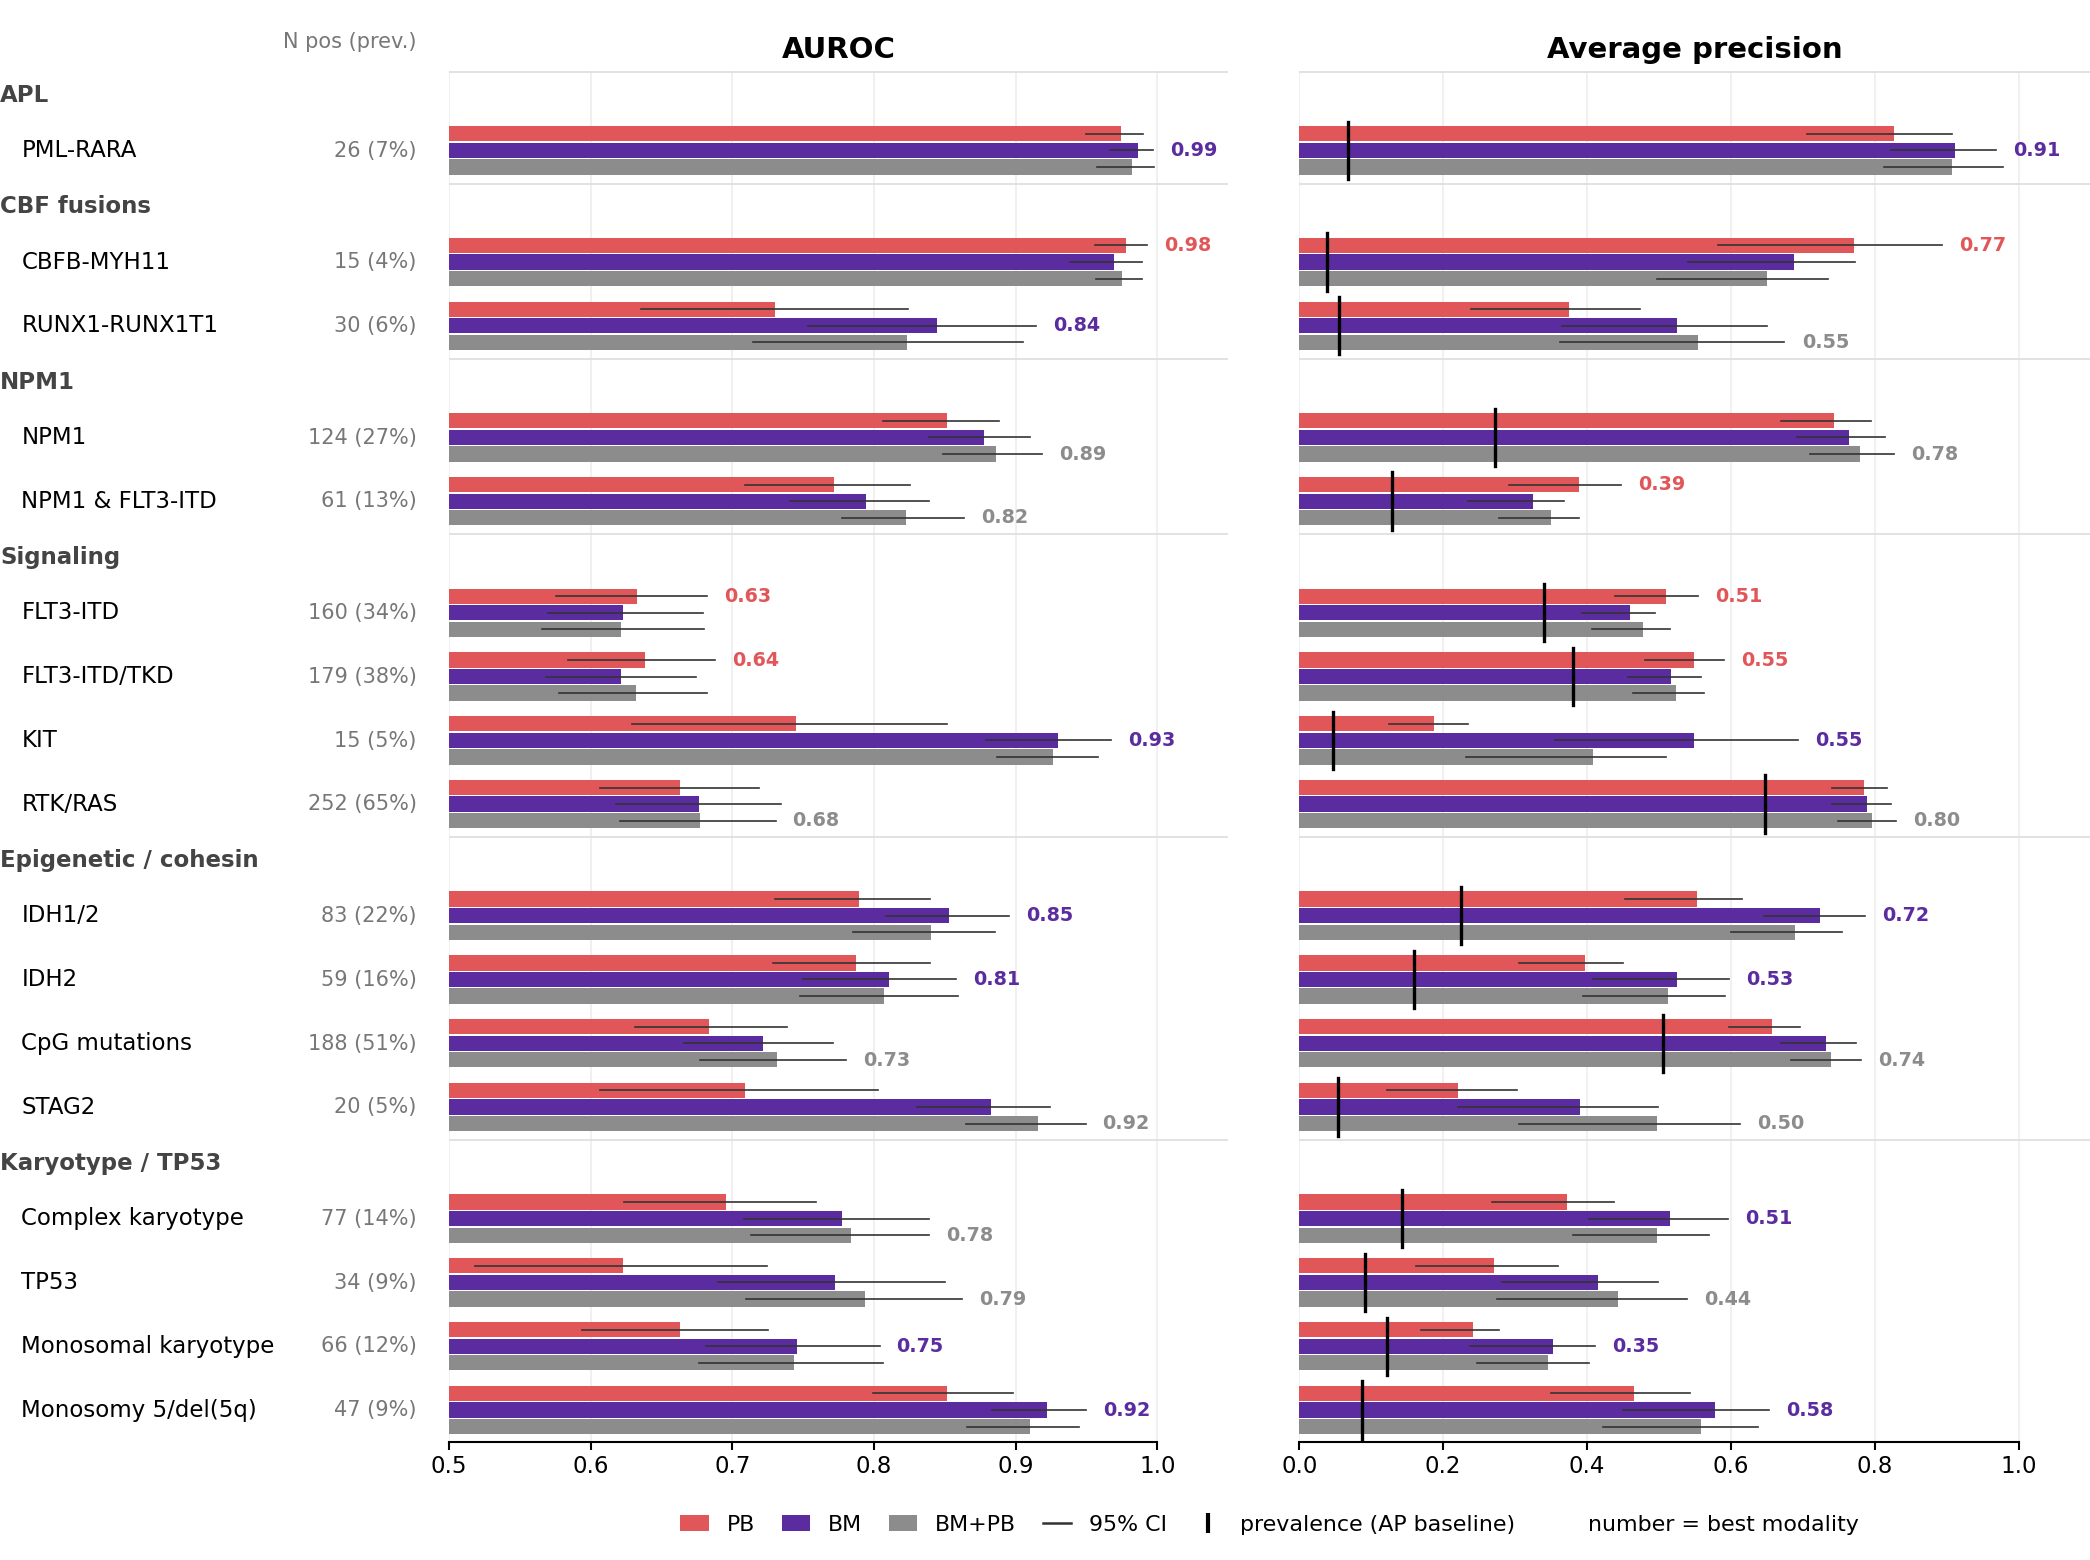

In [2]:
external(C.AML_MIL_FIGS / "fig2_discovery_performance", "Fig2_discovery_performance")

**What it shows (legend draft):** 

**Key observations:**
-

**Caveats / open questions:**
-

## Figure 3 — External validation

Built in aml-mil (`fig3_external_validation`).

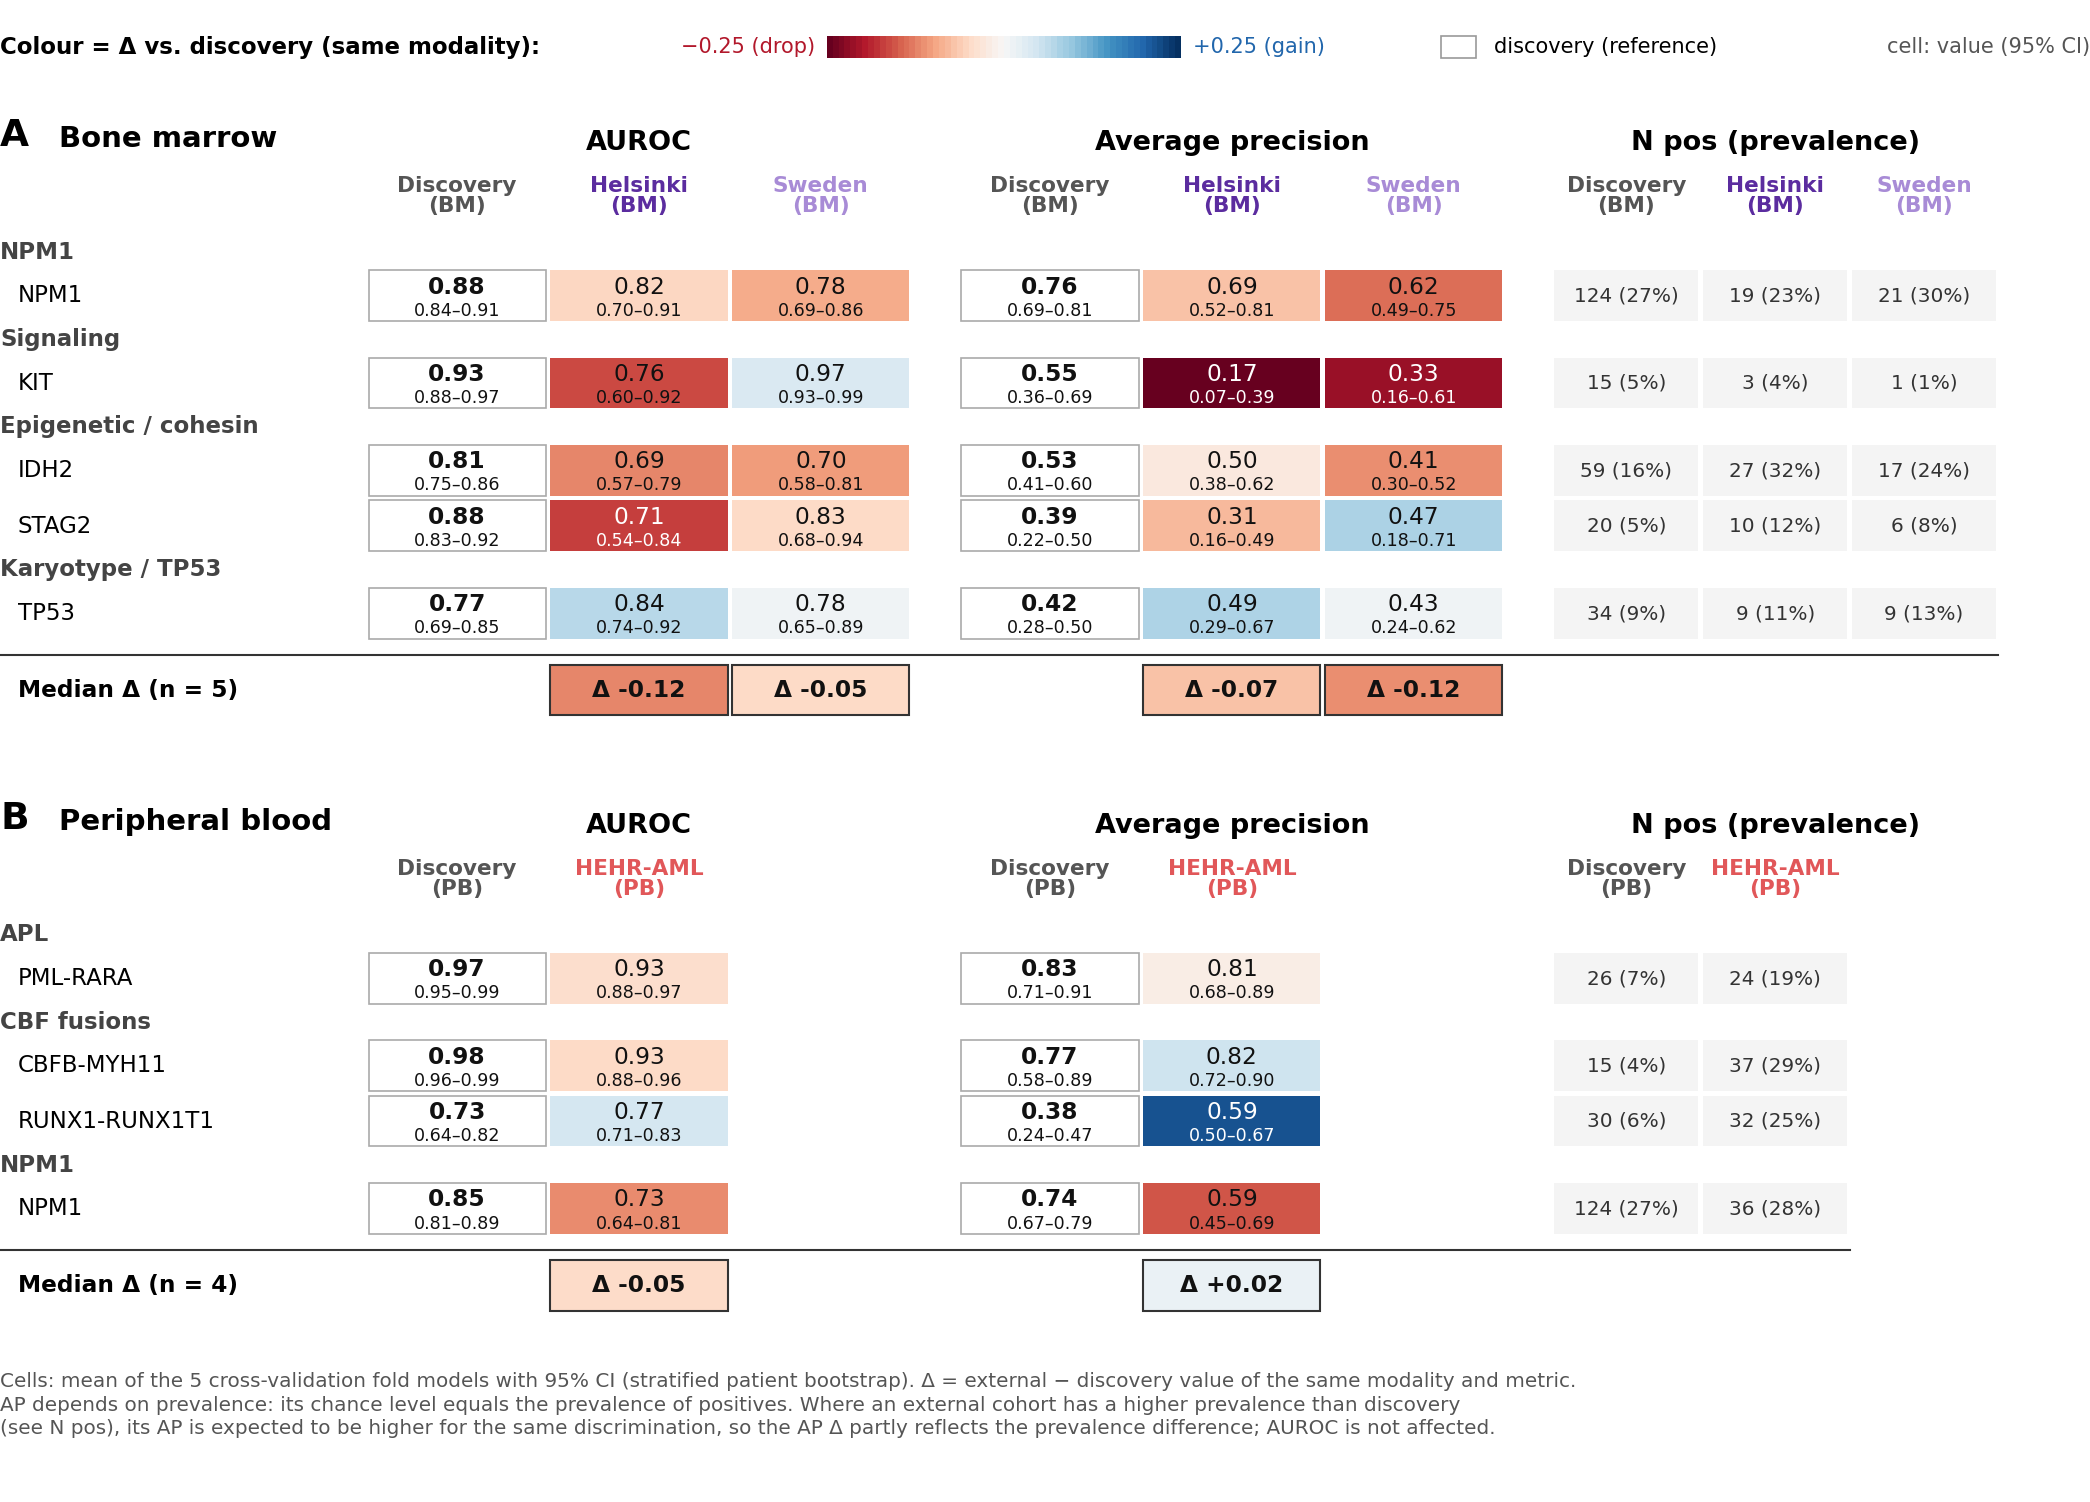

In [3]:
external(C.AML_MIL_FIGS / "fig3_external_validation", "Fig3_external_validation")

**What it shows (legend draft):** 

**Key observations:**
-

**Caveats / open questions:**
-

## Figure 4 — Bone marrow: composition, dysplasia, attention and morphometry

/home/mikkop/projects/2-mut-pred/mut-pred-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/mikkop/projects/2-mut-pred/mut-pred-analysis/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


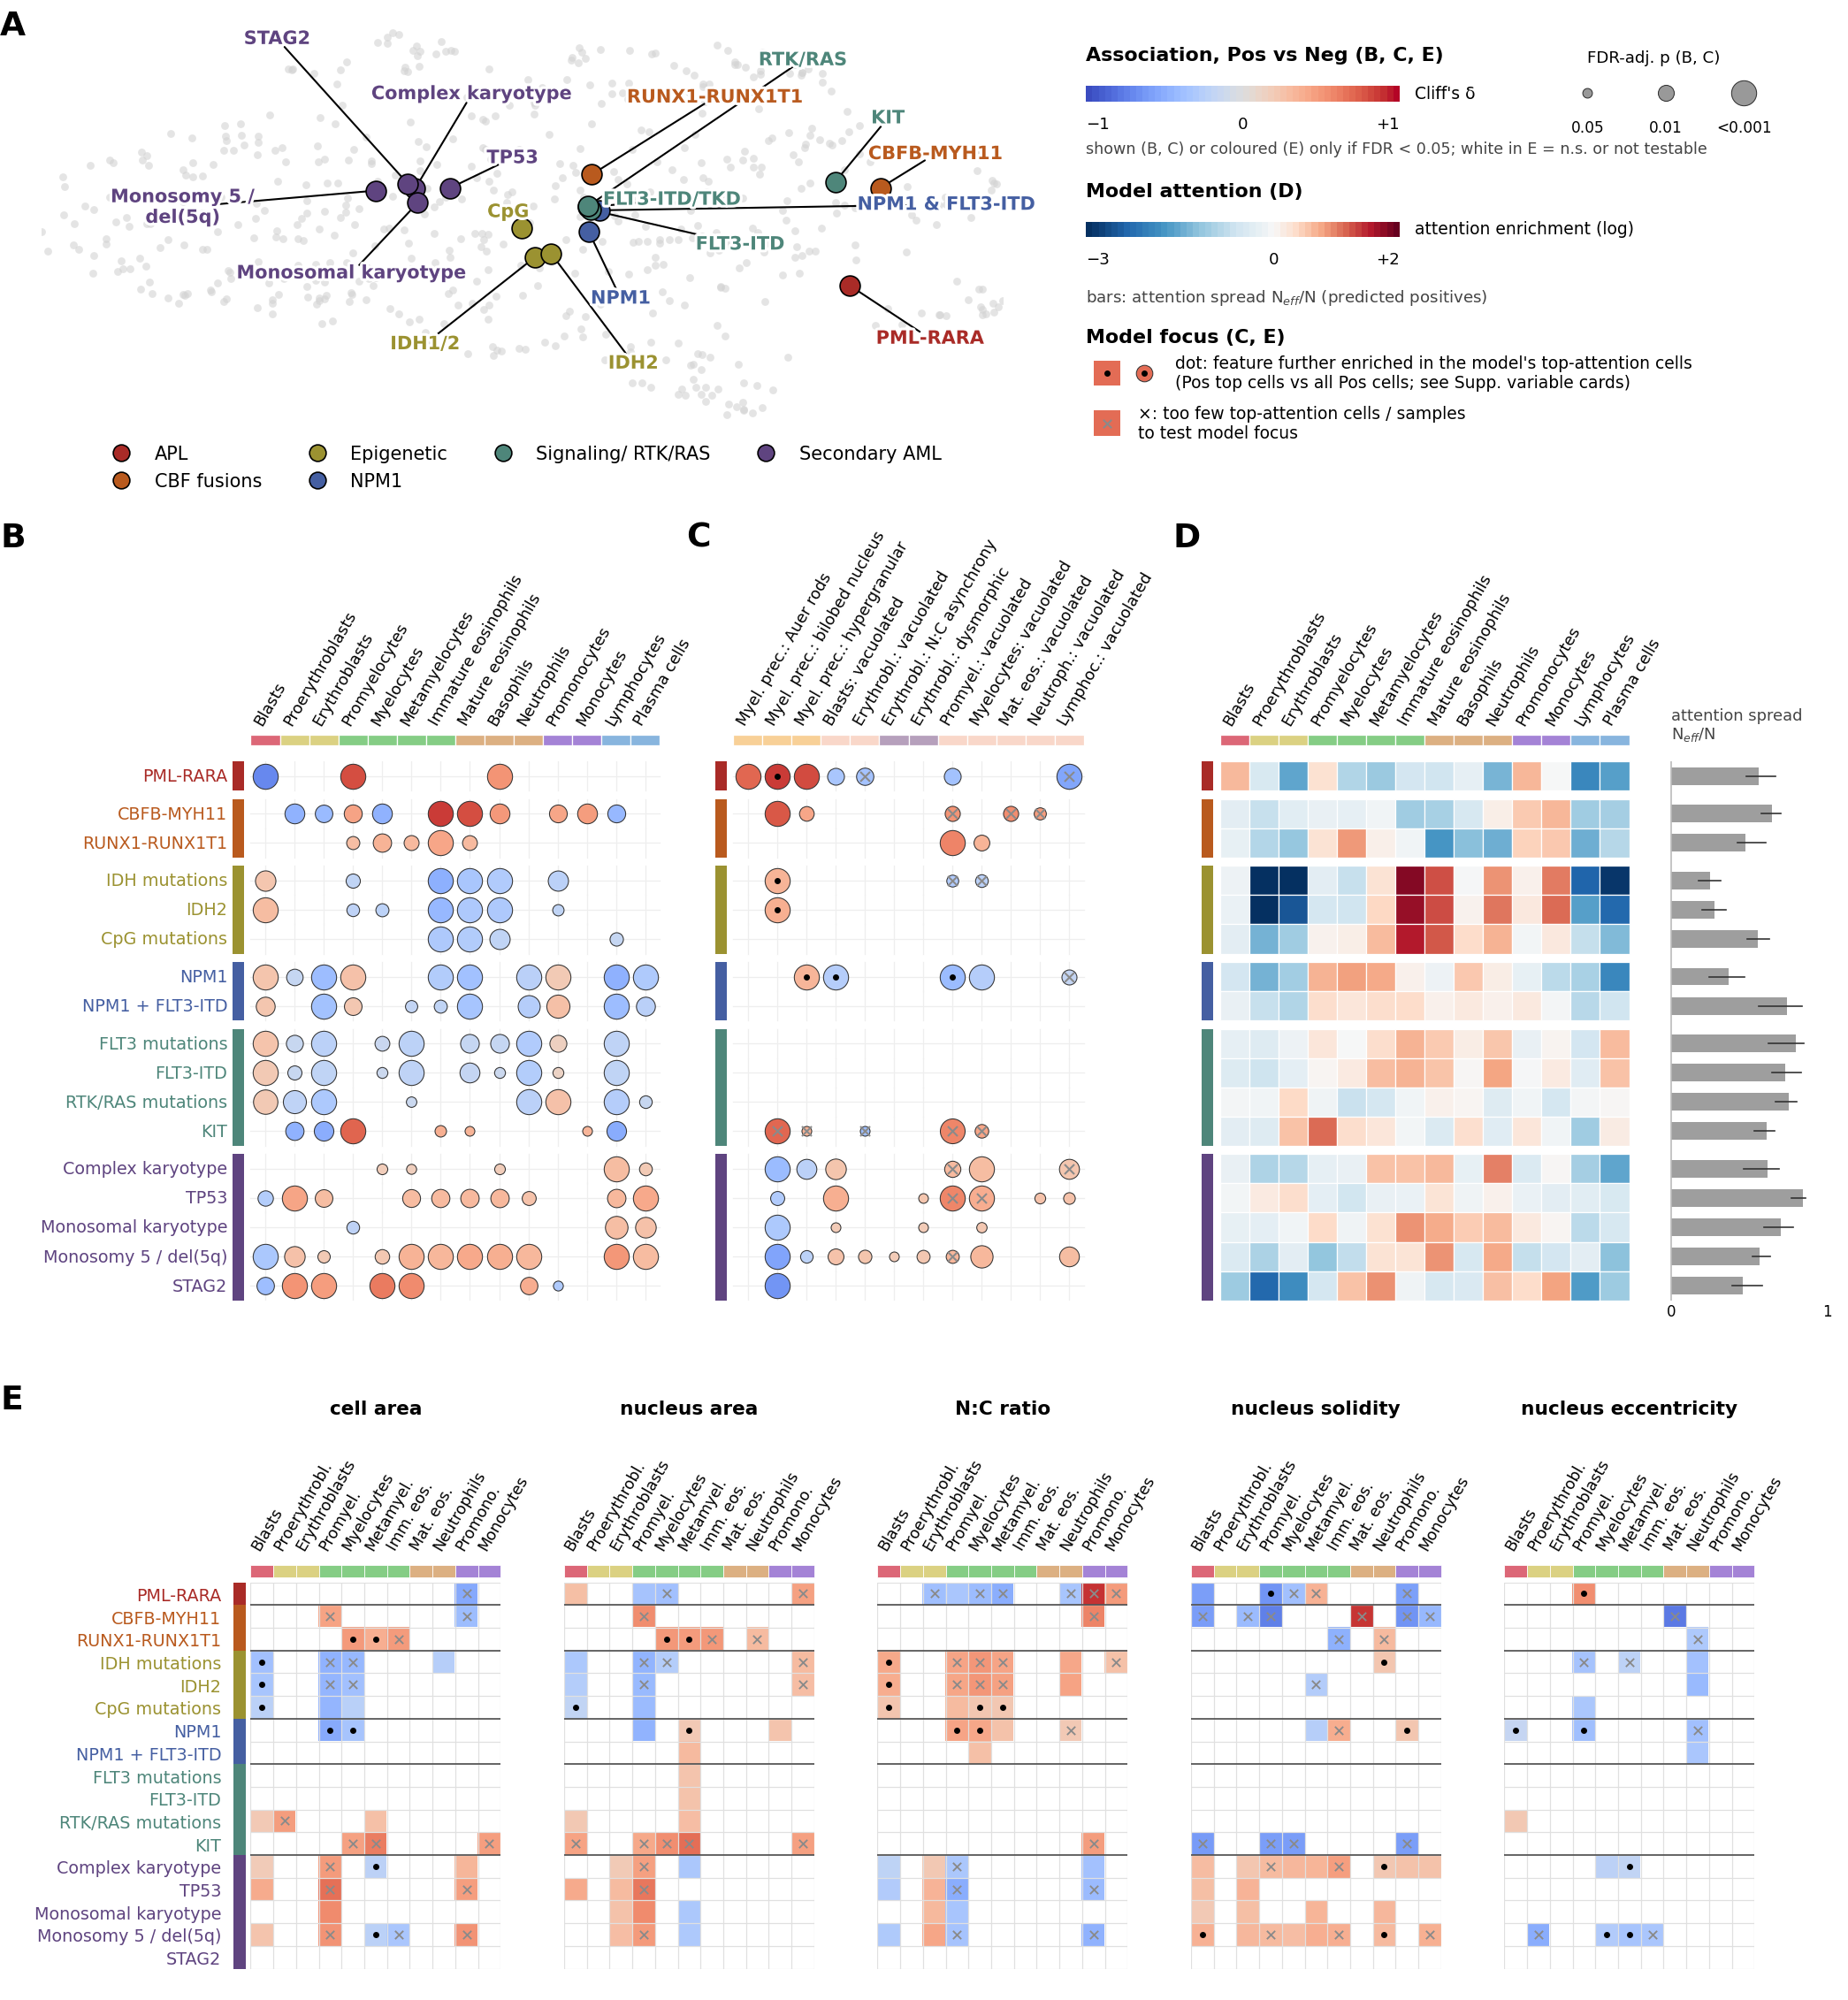

In [4]:
show(fig4.make("BM"), "Fig4_BM")

**What it shows (legend draft):** A, UMAP of sample-level morphology (features associated with ≥ 1 target as in B, C, E); grey = samples, large dots = centroid of the samples positive for each target. B, cell proportions; C, dysplasia: balloons = Pos vs Neg association (colour = Cliff's δ, size = FDR-adjusted p; shown if FDR < 0.05). D, attention enrichment of each cell type in predicted positives (log); bars = attention spread N_eff/N (median, IQR). E, morphometry (cell area, nucleus area, N:C ratio, nucleus solidity, nucleus eccentricity) per cell type, coloured if FDR < 0.05. C, E: dot = feature further enriched in the model's top-attention cells; grey × = too few top-attention cells / samples to test. Tests require ≥ 10 samples per group.

**Key observations:**
-

**Caveats / open questions:**
- Minimum group size (≥ 10 samples per group, `MIN_SAMPLES` in `extract_fig4_fingerprint_results.py`) is kept. Without it (min 3), BM gains 16 weak associations from 5–9 positive samples, notably megakaryocyte nucleus shape (solidity, eccentricity, compactness) in complex karyotype (n = 9) and −5/del(5q) (n = 8), multinucleated megakaryocytes in complex karyotype (n = 9) and hypolobated megakaryocytes in TP53 (n = 5; δ = 0.69) — biologically plausible (MDS-related dysmegakaryopoiesis); mention as exploratory in text / supplement. The extra tests also push 15 well-powered borderline BM associations (FDR 0.04–0.05) above 0.05; PB gains only n = 3–4 associations.

## Figure 5 — Peripheral blood: composition, dysplasia, attention and morphometry

/home/mikkop/projects/2-mut-pred/mut-pred-analysis/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


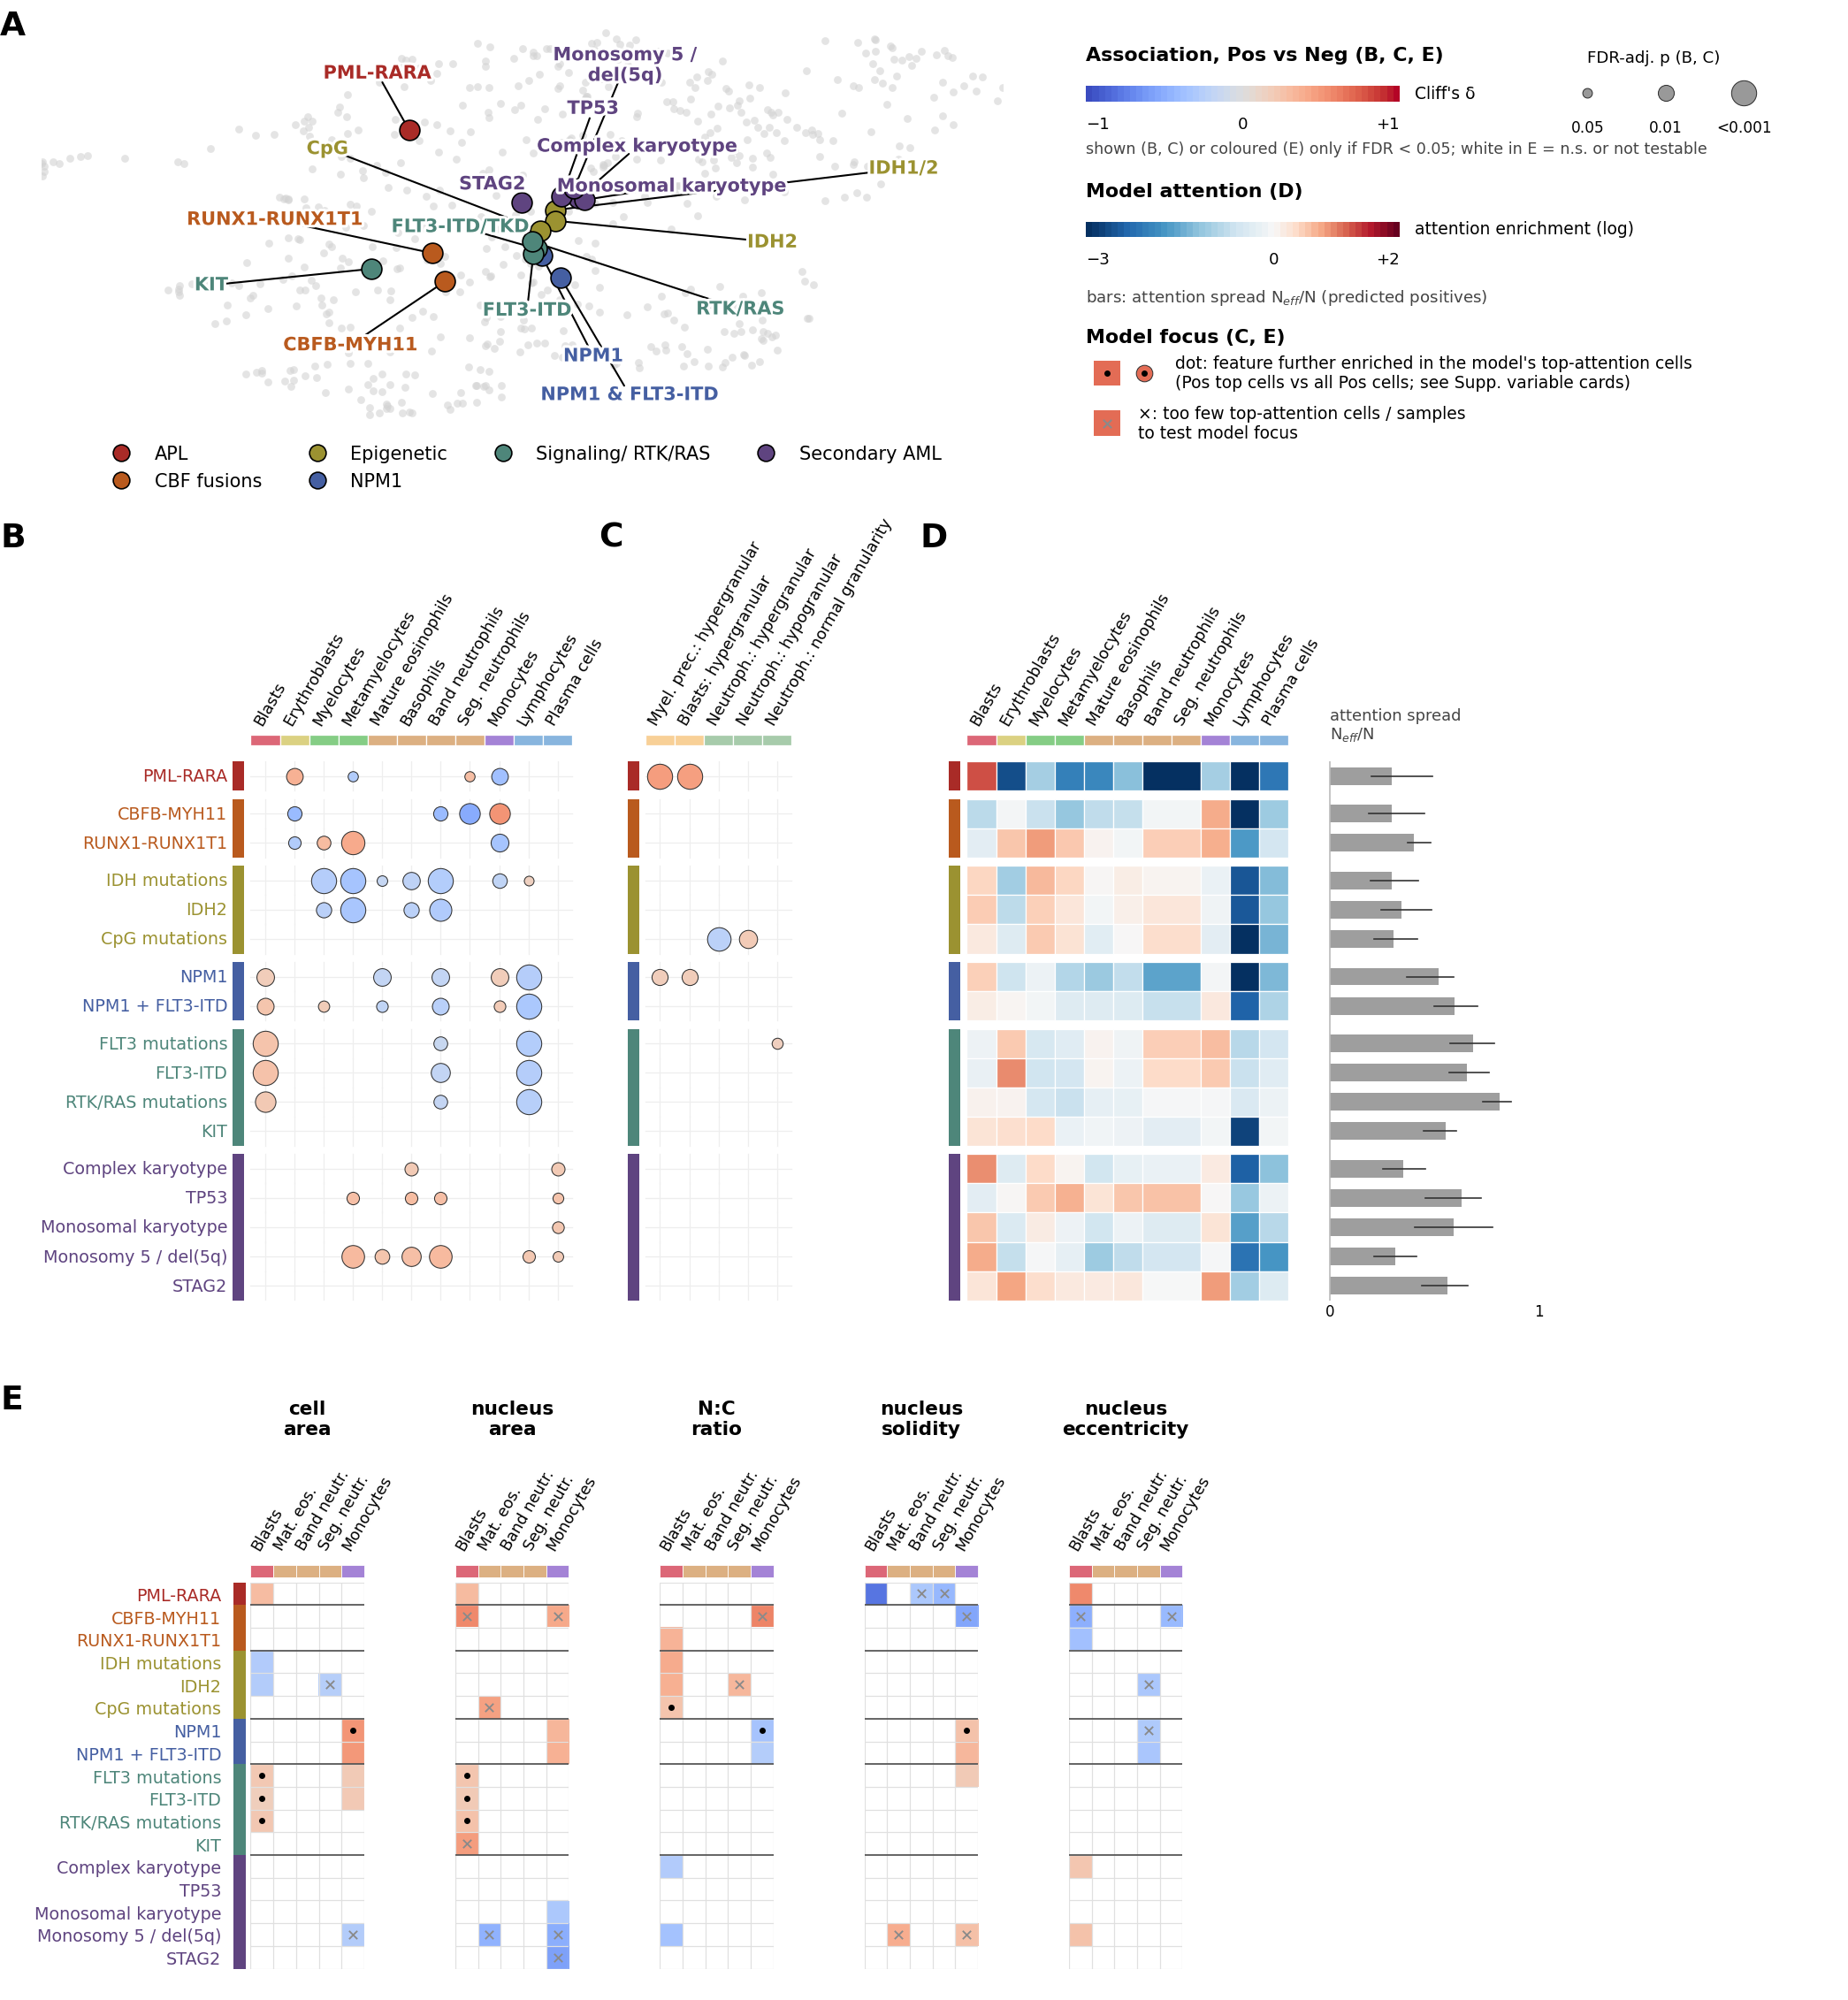

In [5]:
show(fig4.make("PB"), "Fig5_PB")

**What it shows (legend draft):** As Figure 4, PB model. Band and segmented neutrophils share one attention tile (merged class in the PB model).

**Key observations:**
-

**Caveats / open questions:**
-

## Figure 6 — Showcase: cell gallery + morphometry

*Not built yet (synthetic-cell mockup).*

**What it shows (legend draft):** 

**Key observations:**
-

**Caveats / open questions:**
-

## Figure 7 — Clinical impact

*Not built yet.*

**What it shows (legend draft):** 

**Key observations:**
-

**Caveats / open questions:**
-

# Supplementary figures

## Supplementary Figure S1 — Variable cards

*Not built yet (synthetic-cell mockup).*

**What it shows (legend draft):** 

**Key observations:**
-

**Caveats / open questions:**
-

## Supplementary Figure S2 — Top-attention cells by outcome (TP / TN / FP / FN)

*Not built yet (synthetic-cell mockup).*

**What it shows (legend draft):** 

**Key observations:**
-

**Caveats / open questions:**
-

## Supplementary Figure S3 — Errors in context

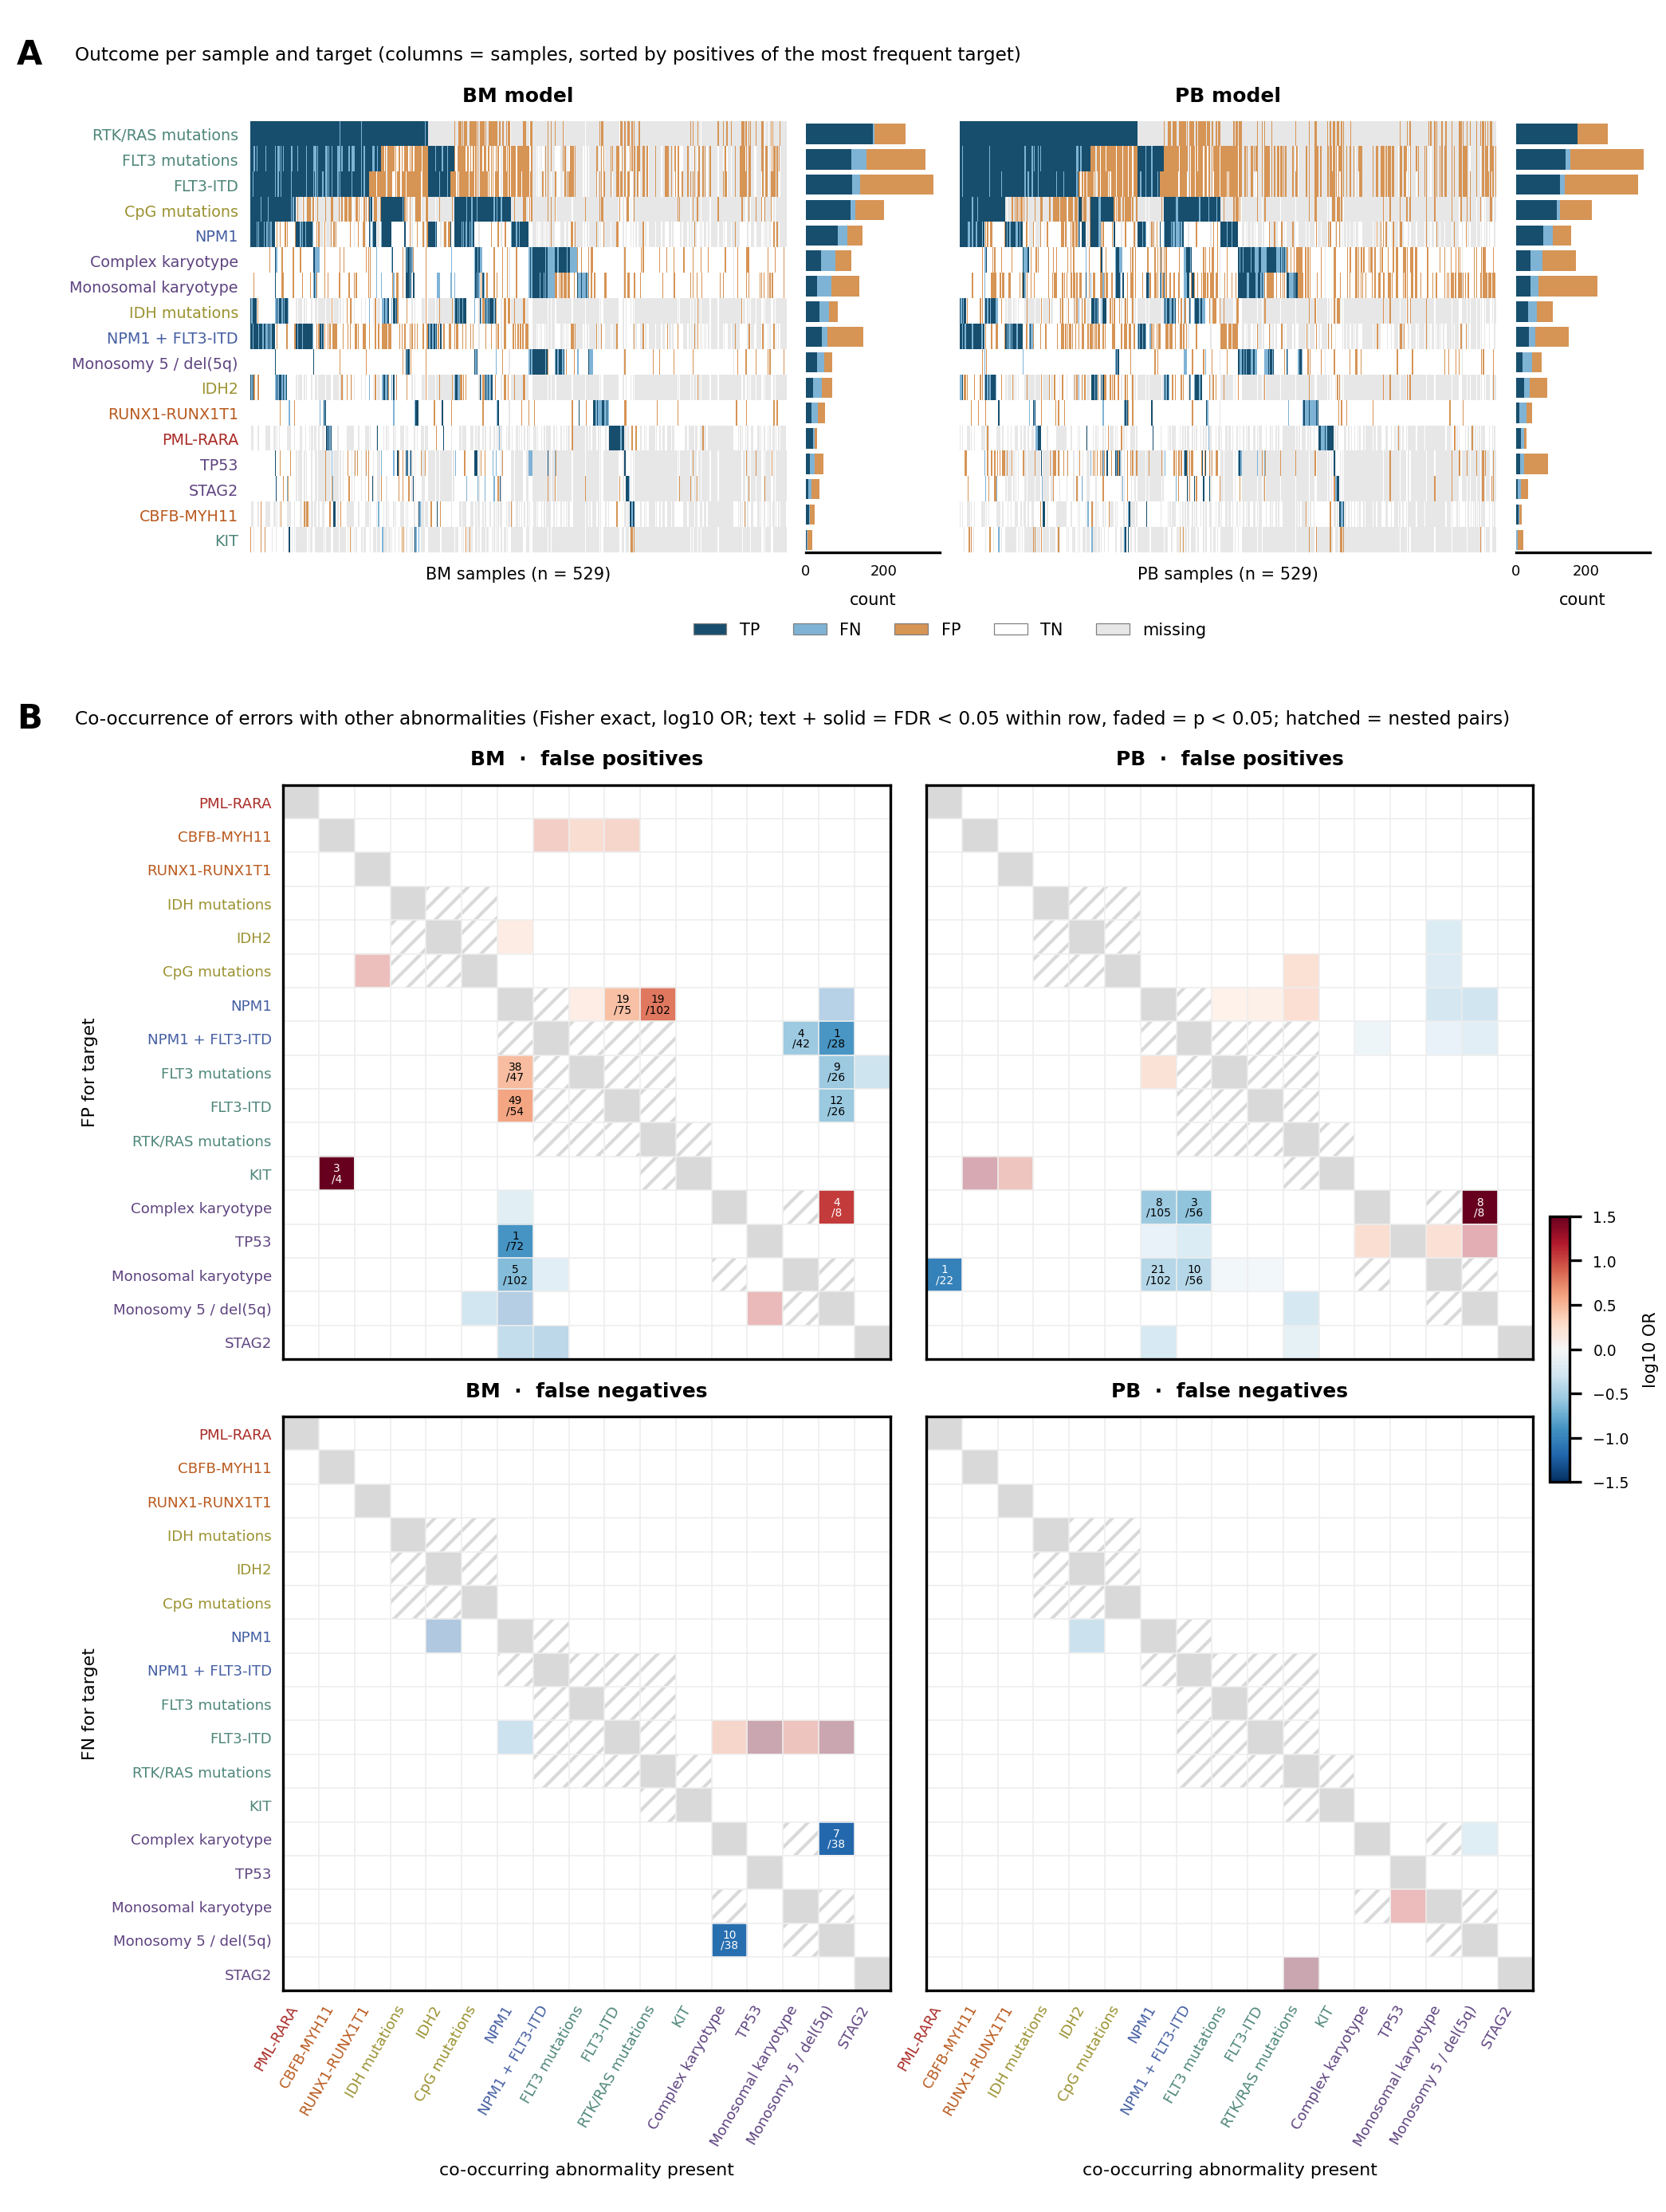

In [6]:
show(errors.errors_in_context(), "S3_errors_in_context")

**What it shows (legend draft):** A, outcome (TP / FN / FP / TN) per sample and target, BM and PB models; bars = counts. B, co-occurrence of false positives (top) and false negatives (bottom) with other abnormalities: Fisher exact log10 OR (Haldane +0.5), solid + counts where FDR < 0.05 (BH within row), faded where p < 0.05; nested target pairs hatched.

**Key observations:**
-

**Caveats / open questions:**
-

## Supplementary Figure S4 — Shift of misclassified samples: composition, dysplasia, QC

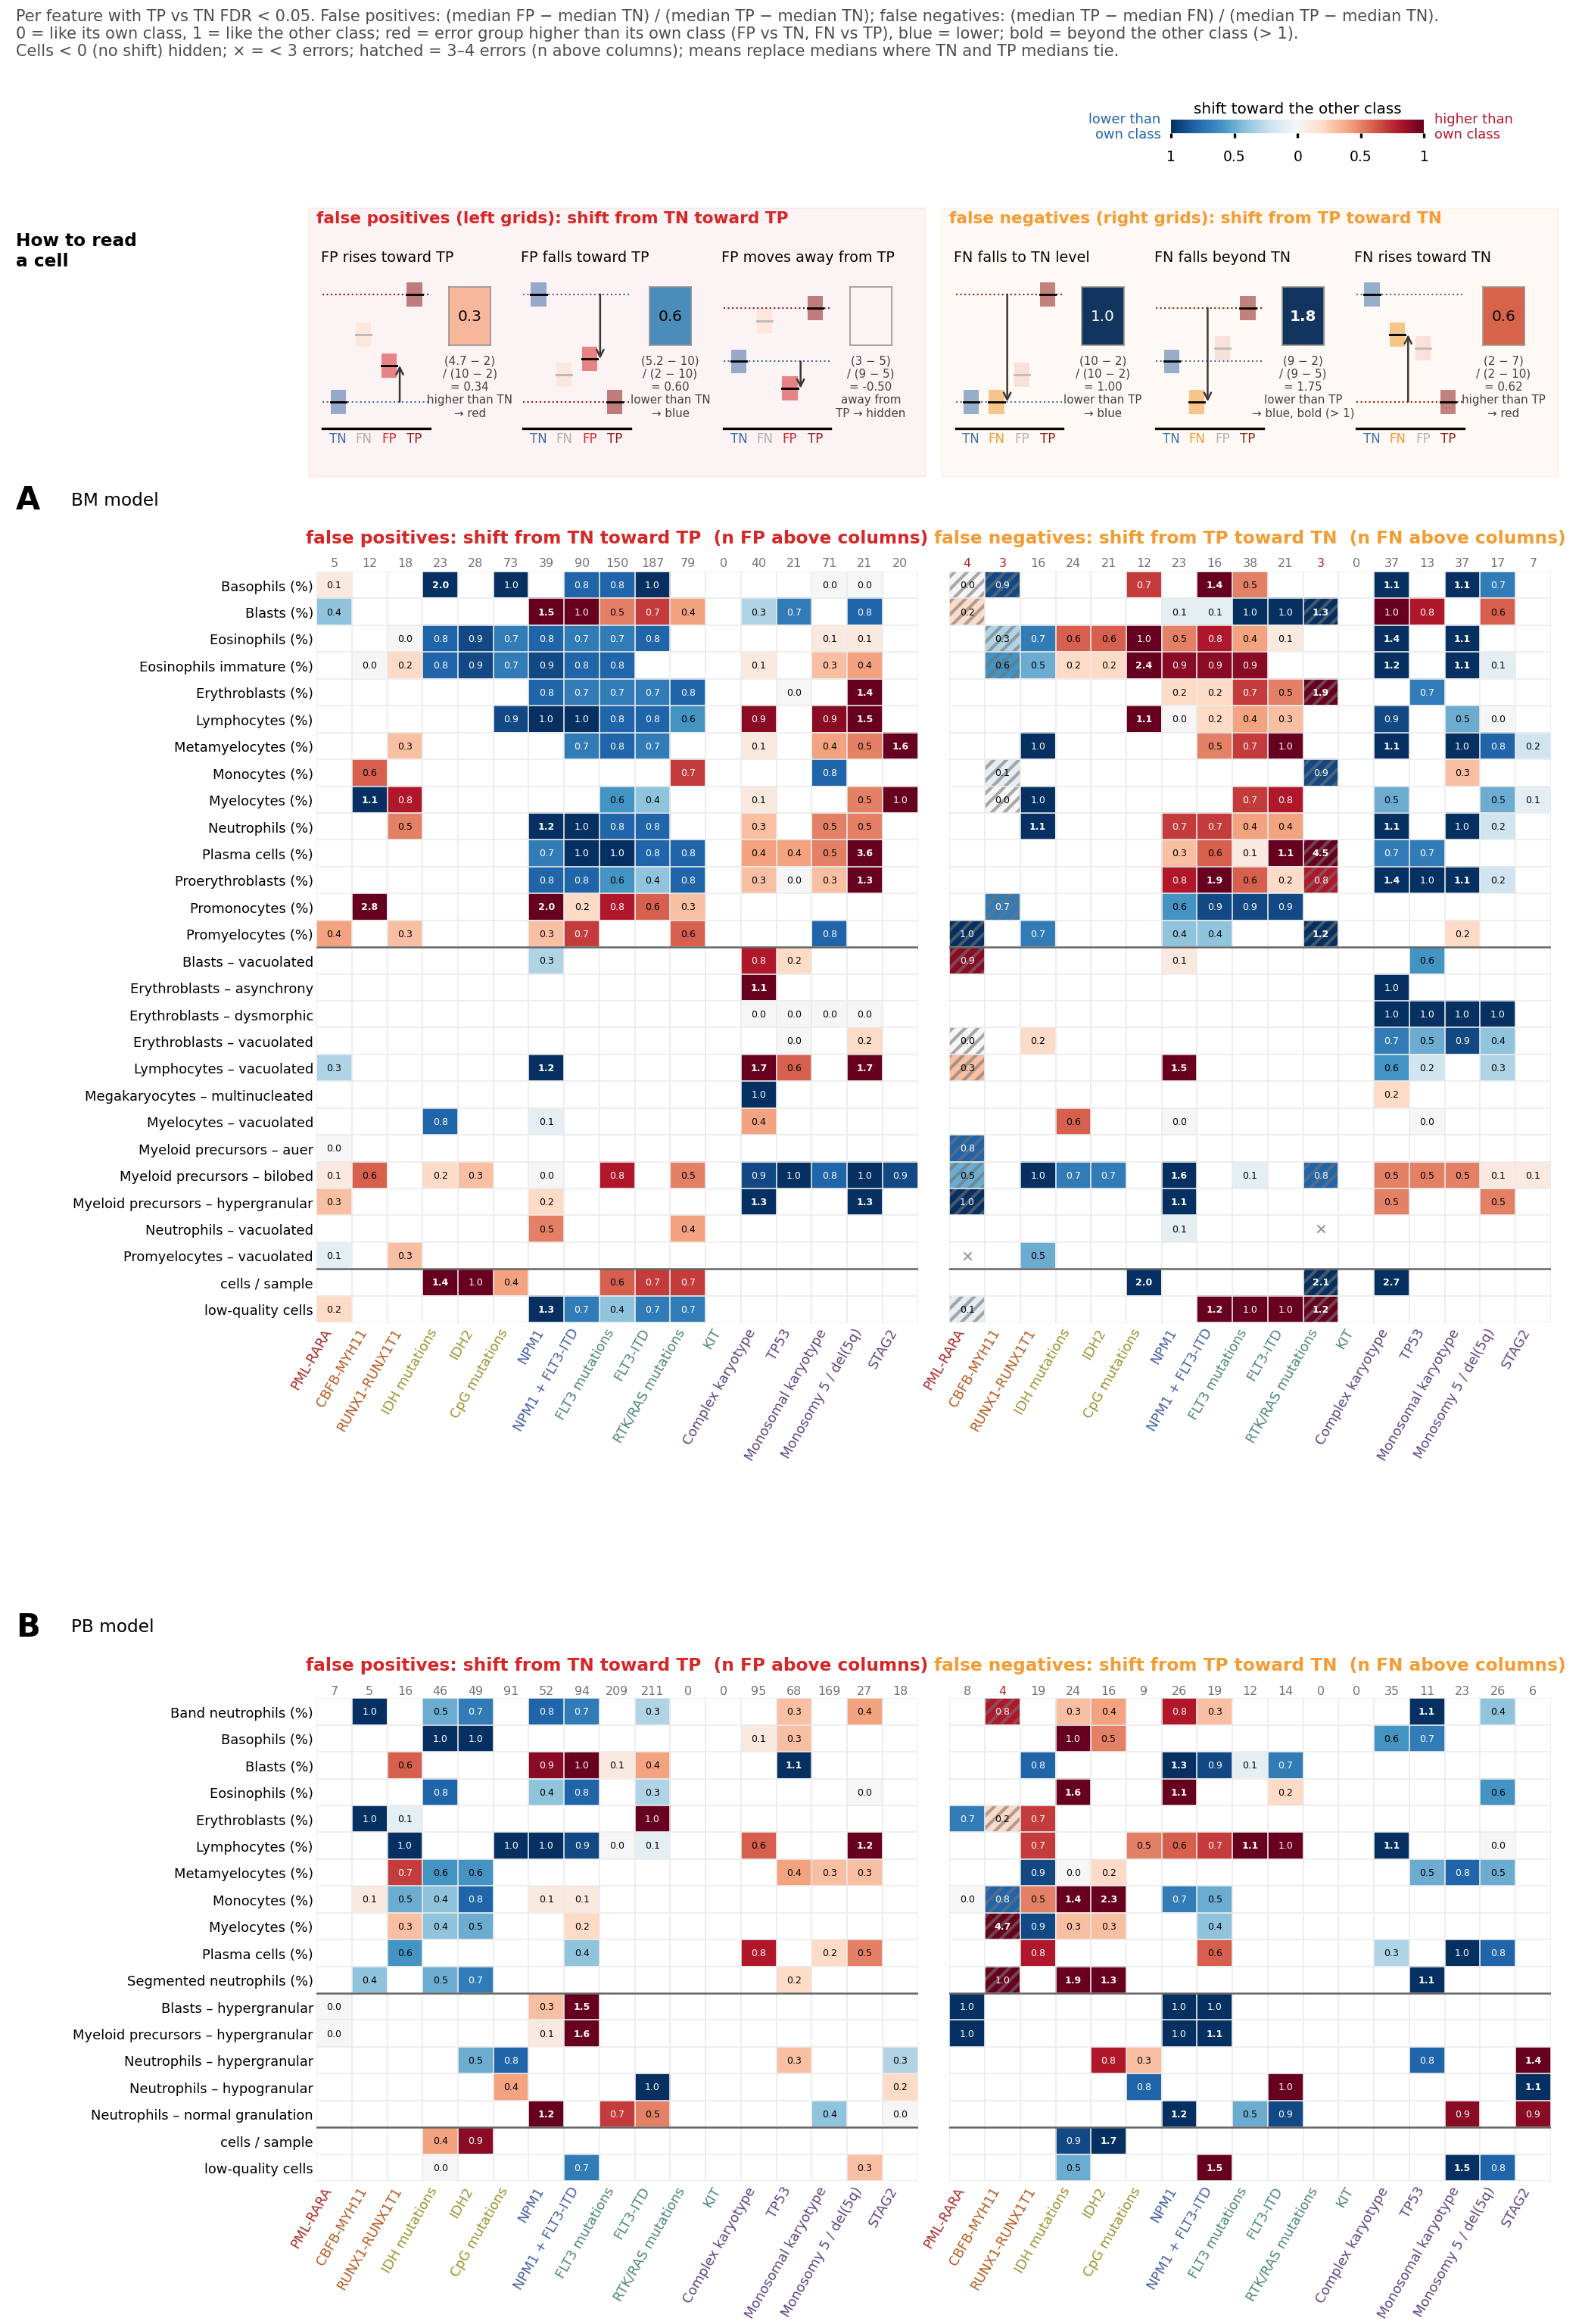

In [7]:
show(errors.shift_grid(), "S4_error_shift_grid")

**What it shows (legend draft):** Per feature with TP vs TN FDR < 0.05: position of the FP median between TN (0) and TP (1), and of the FN median between TP (0) and TN (1). Red / blue = error group higher / lower than its own class; bold = beyond the other class; cells < 0 hidden; × = < 3 errors; hatched = 3–4 errors. Key at top.

**Key observations:**
-

**Caveats / open questions:**
-

## Supplementary Figures S5–S6 — Shift of misclassified samples: morphometry (BM, PB)

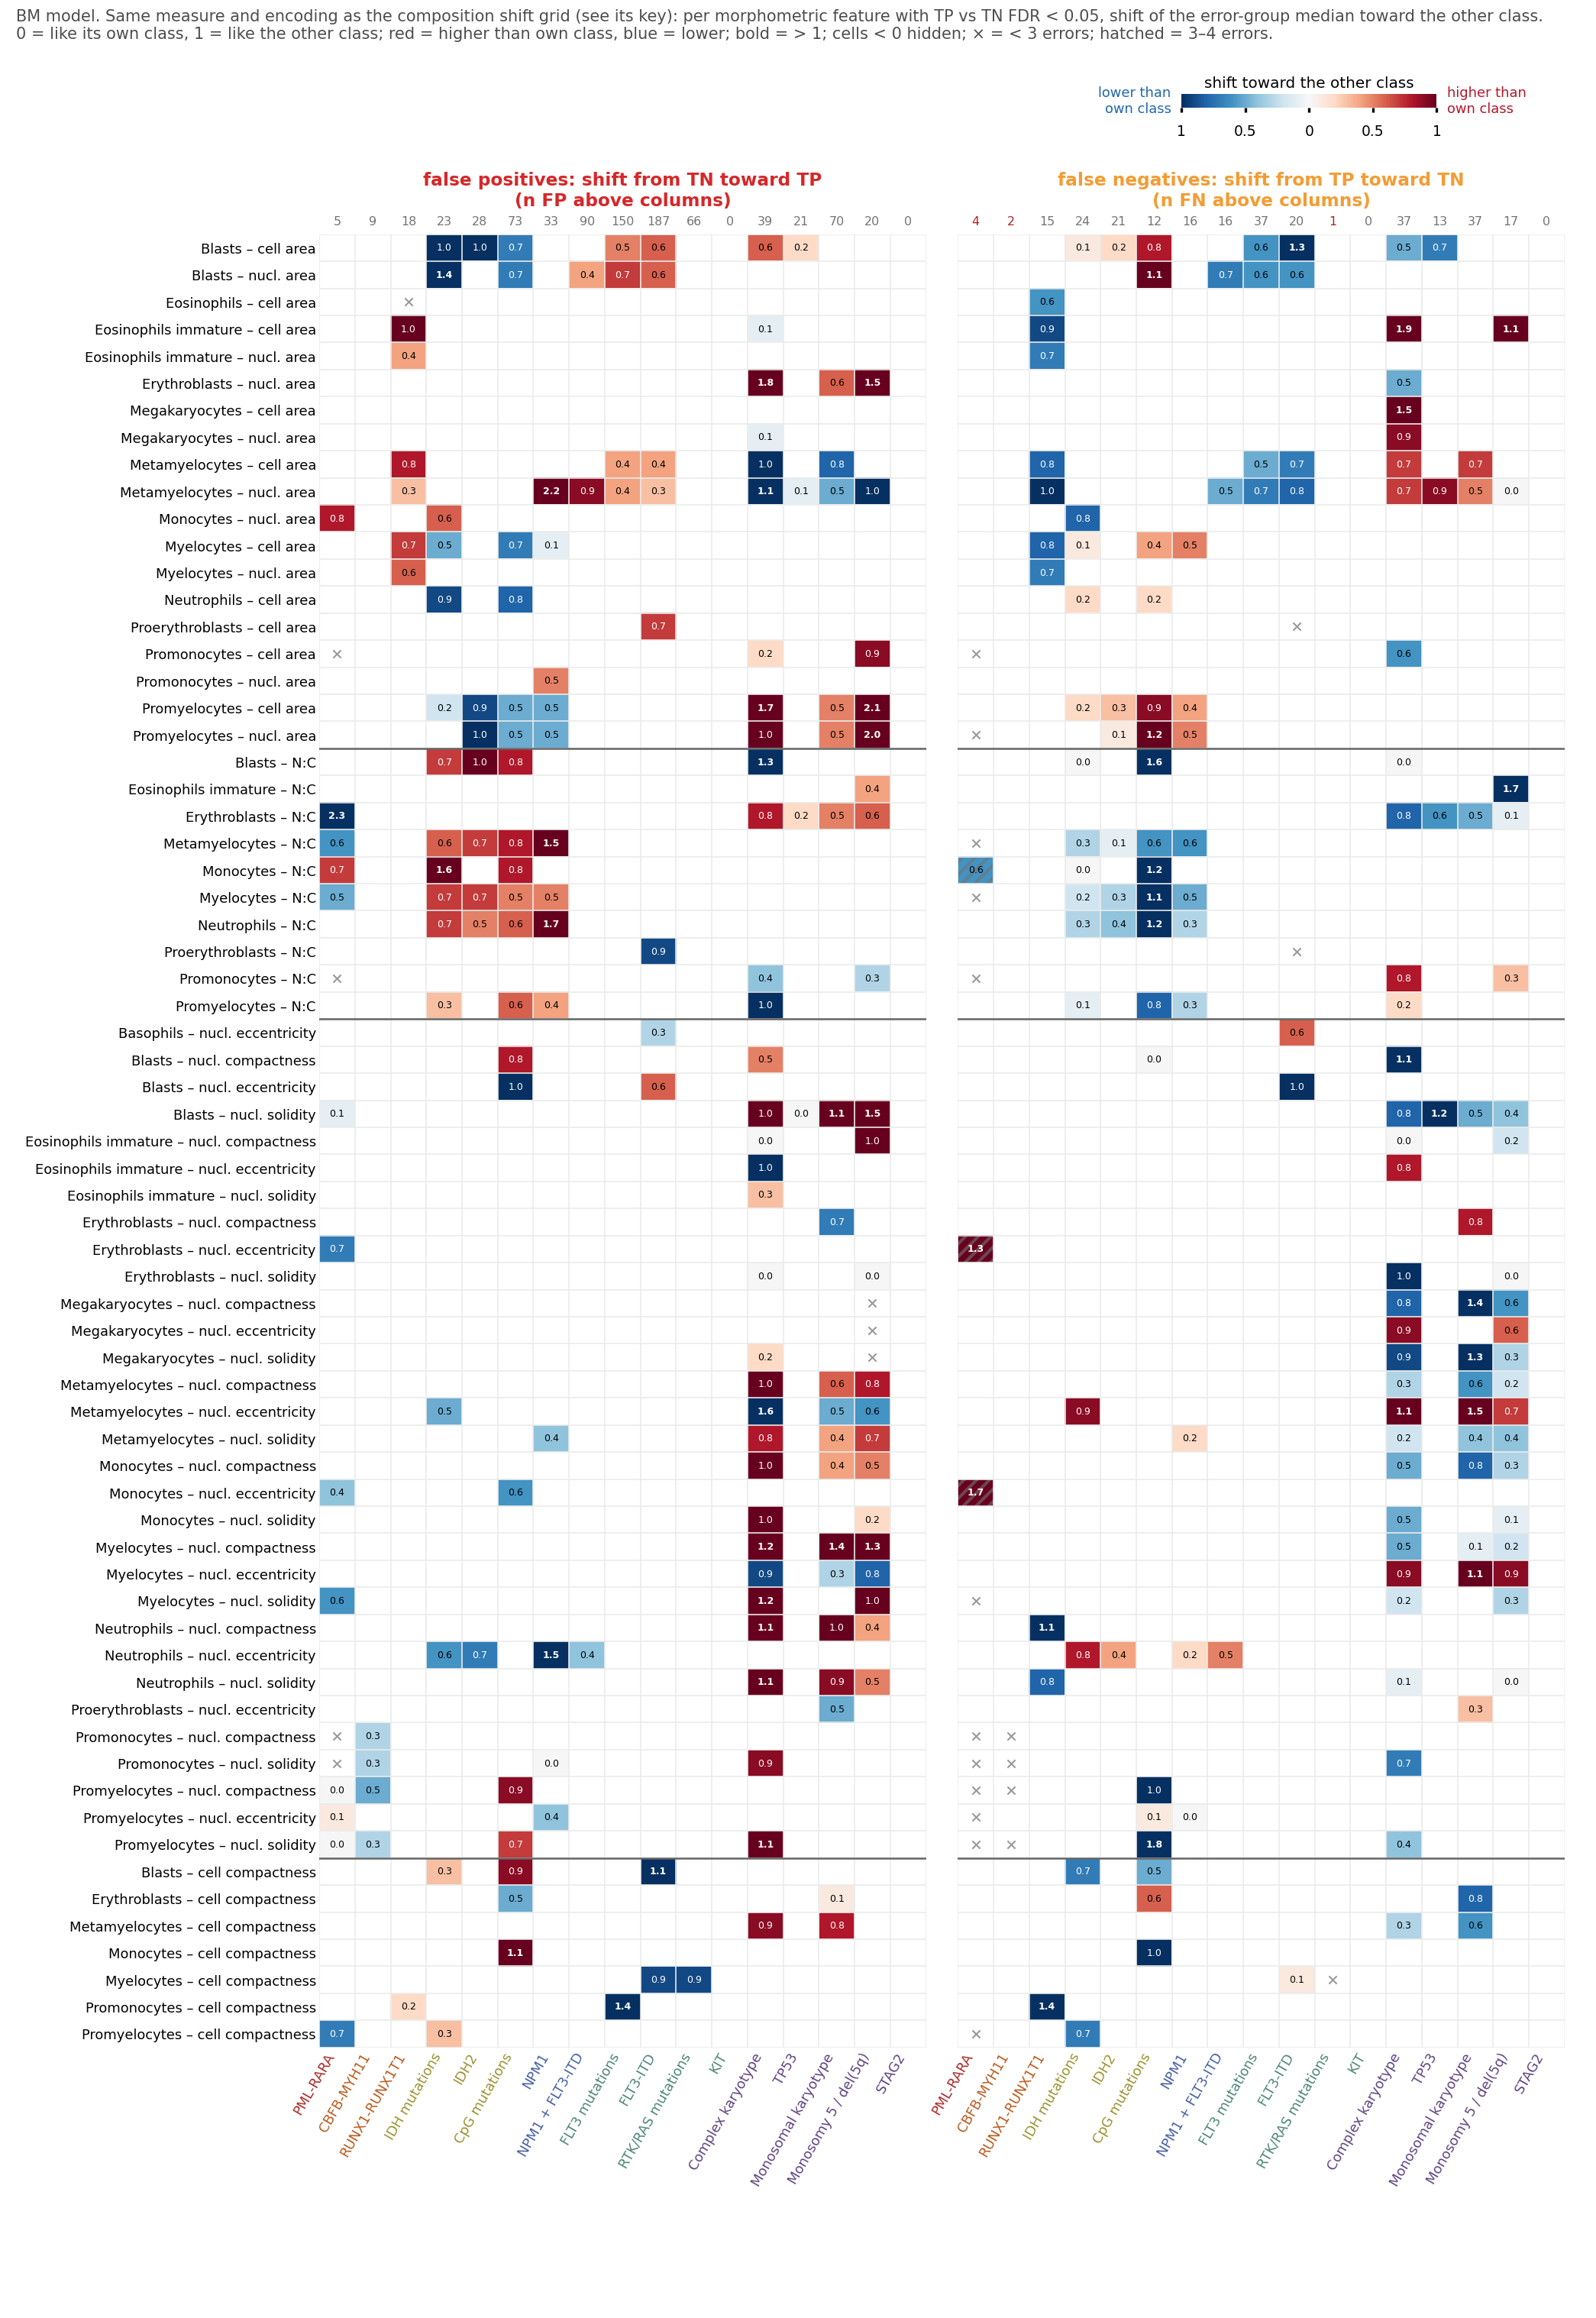

In [8]:
show(errors.shift_grid_morph("BM"), "S5_error_shift_morph_BM")

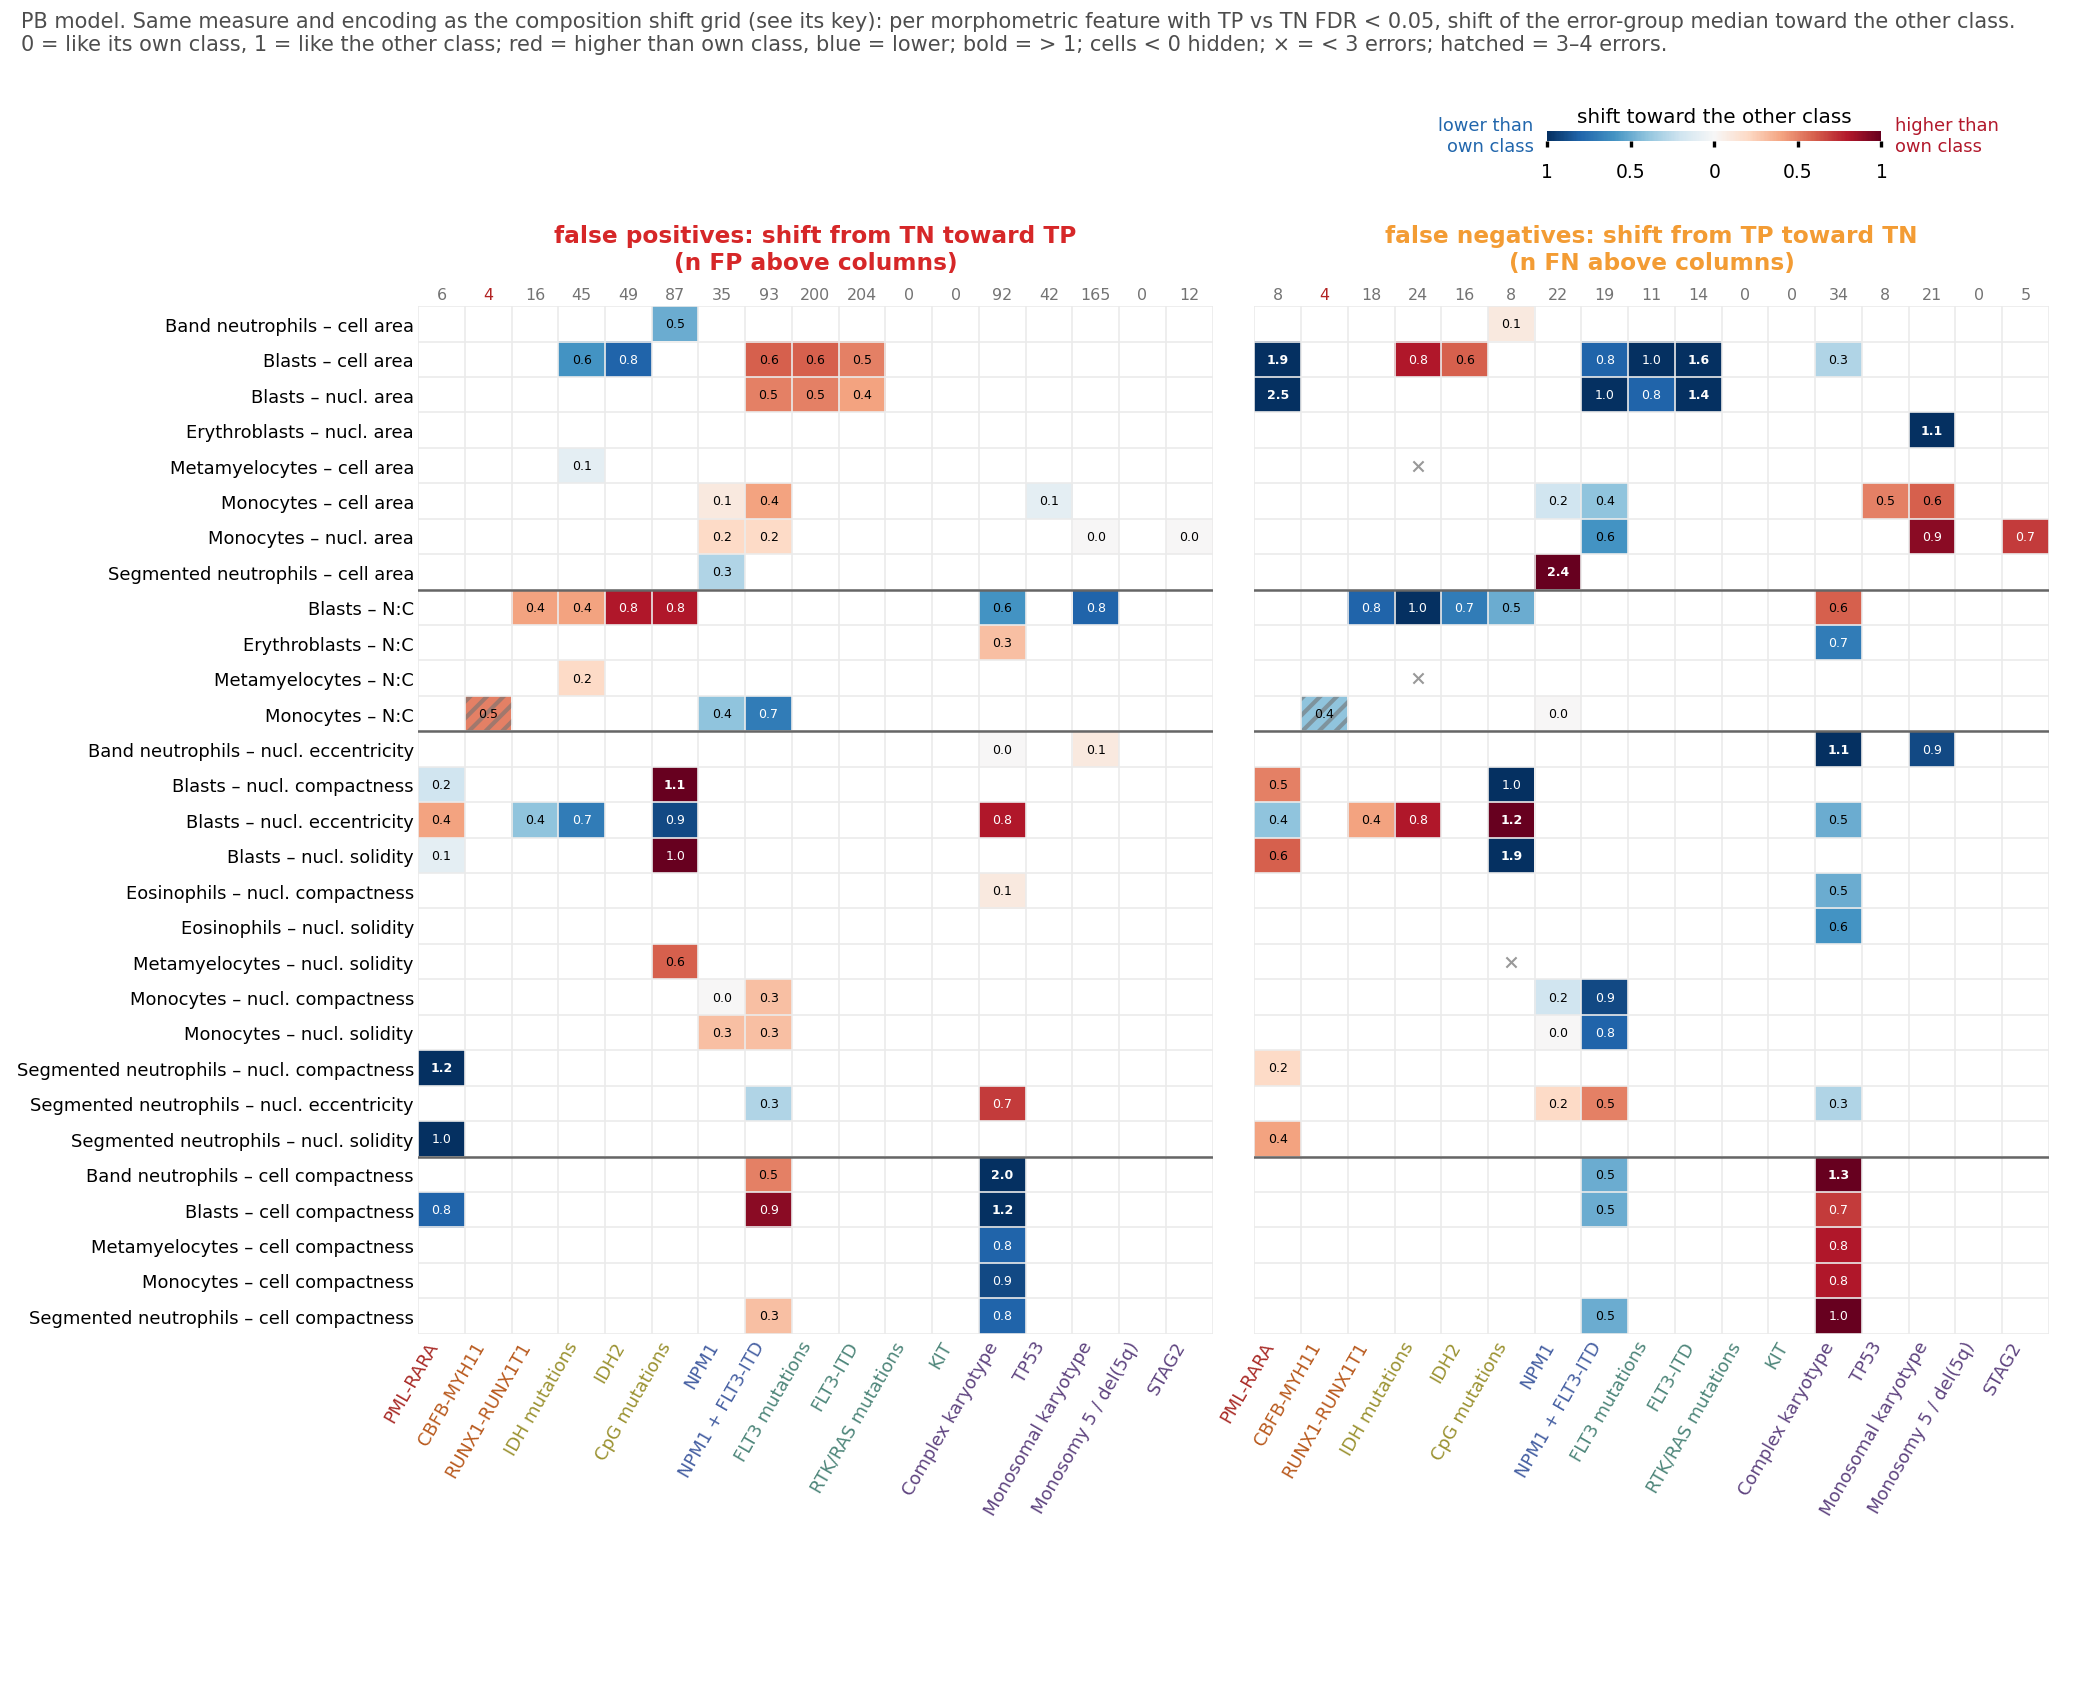

In [9]:
show(errors.shift_grid_morph("PB"), "S6_error_shift_morph_PB")

**What it shows (legend draft):** As S4 for morphometric features; rows = features shown in either grid.

**Key observations:**
-

**Caveats / open questions:**
-

## Supplementary Figure S7 — Variable-specific examples

Edit `PANELS`: one sub-figure per `(variable, modality, feature)`. Feature = a sample-level column of
`load_cohort(modality)` (e.g. `"Promyelocytes_proportion"`, `"Blasts_nucleus_area_median"`), `"low_quality_all"` /
`"n_cells"`, or a top-attention summary (e.g. `"top_apl_bilobed"`). Placeholder selection.

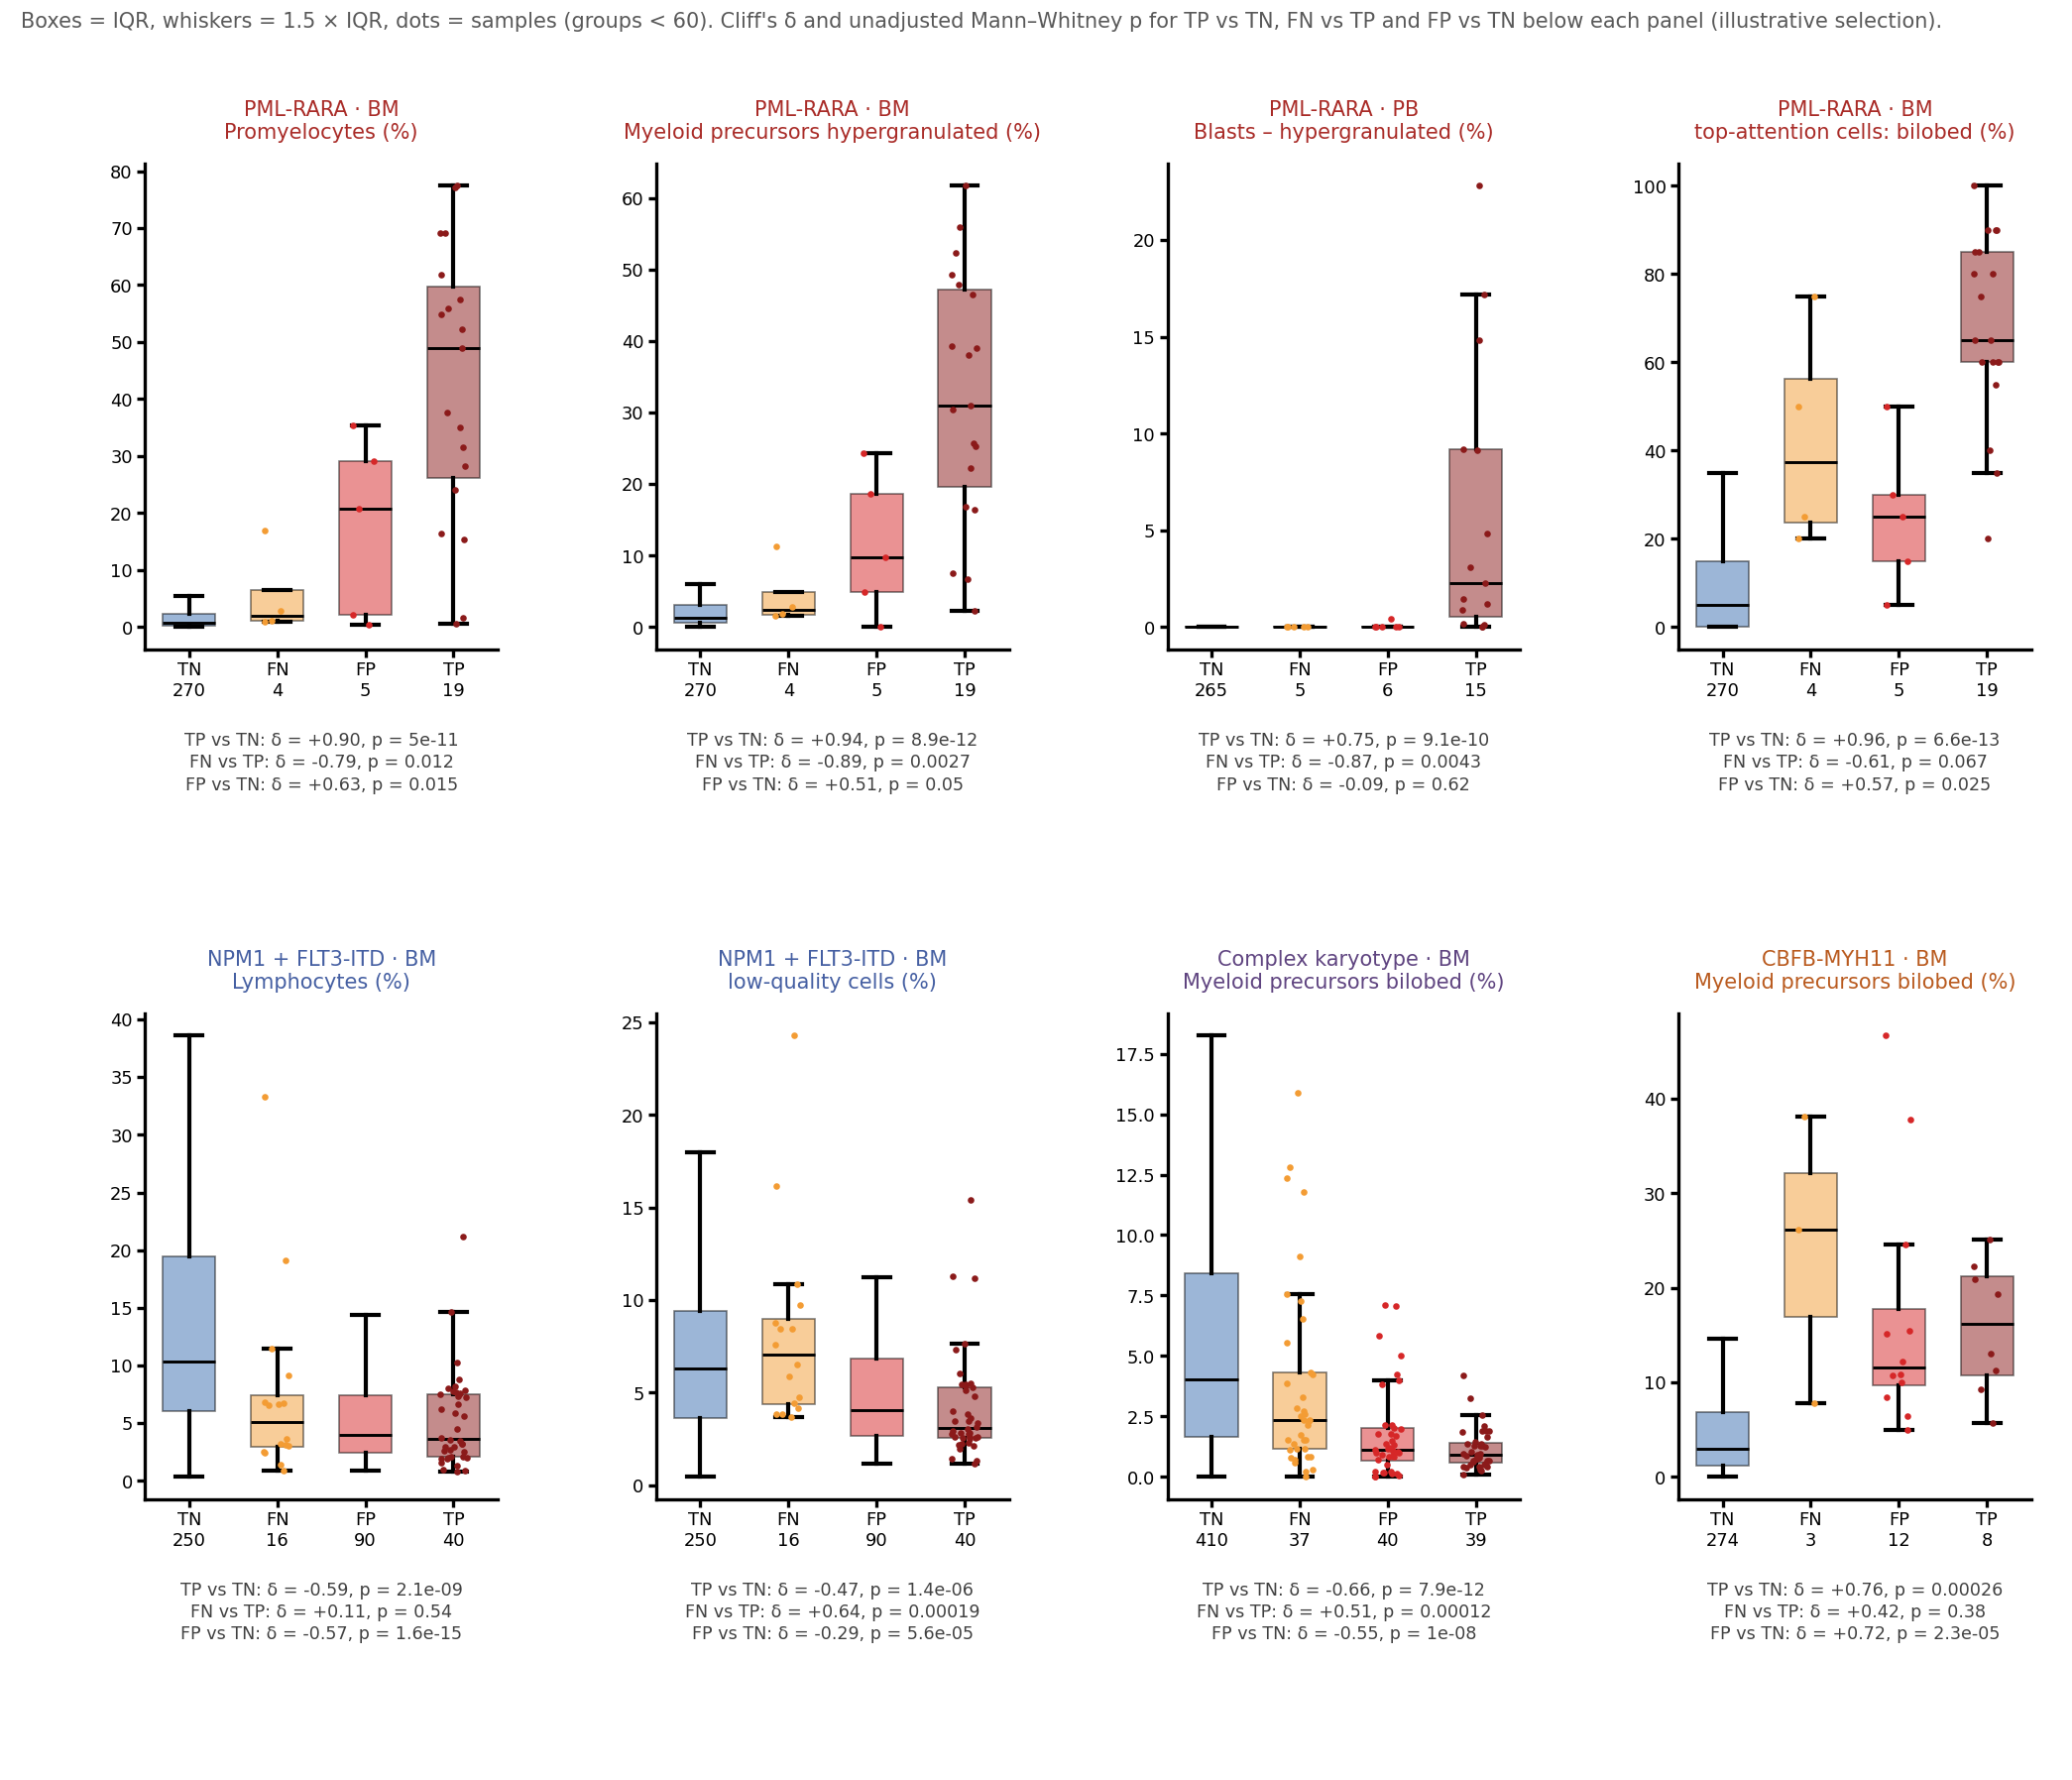

In [10]:
PANELS = [("PML-RARA", "BM", "Promyelocytes_proportion"),
          ("PML-RARA", "BM", "Myeloid_precursors_hypergranulated_proportion"),
          ("PML-RARA", "PB", "Blasts-apl_hypergranulated_proportion"),
          ("PML-RARA", "BM", "top_apl_bilobed"),
          ("NPM1_AND_FLT3_ITD", "BM", "Lymphocytes_proportion"),
          ("NPM1_AND_FLT3_ITD", "BM", "low_quality_all"),
          ("complex_karyotype", "BM", "Myeloid_precursors_bilobed_proportion"),
          ("CBFB-MYH11", "BM", "Myeloid_precursors_bilobed_proportion")]
show(errors.variable_examples(PANELS), "S7_variable_examples")

**What it shows (legend draft):** Four-group distributions (TN, FN, FP, TP); Cliff's δ and unadjusted Mann–Whitney p (illustrative).

**Key observations:**
-

**Caveats / open questions:**
-

## Supplementary Figure S8 — Calibration (BM)

Built in aml-mil (`supp_calibration_curves_BM`).

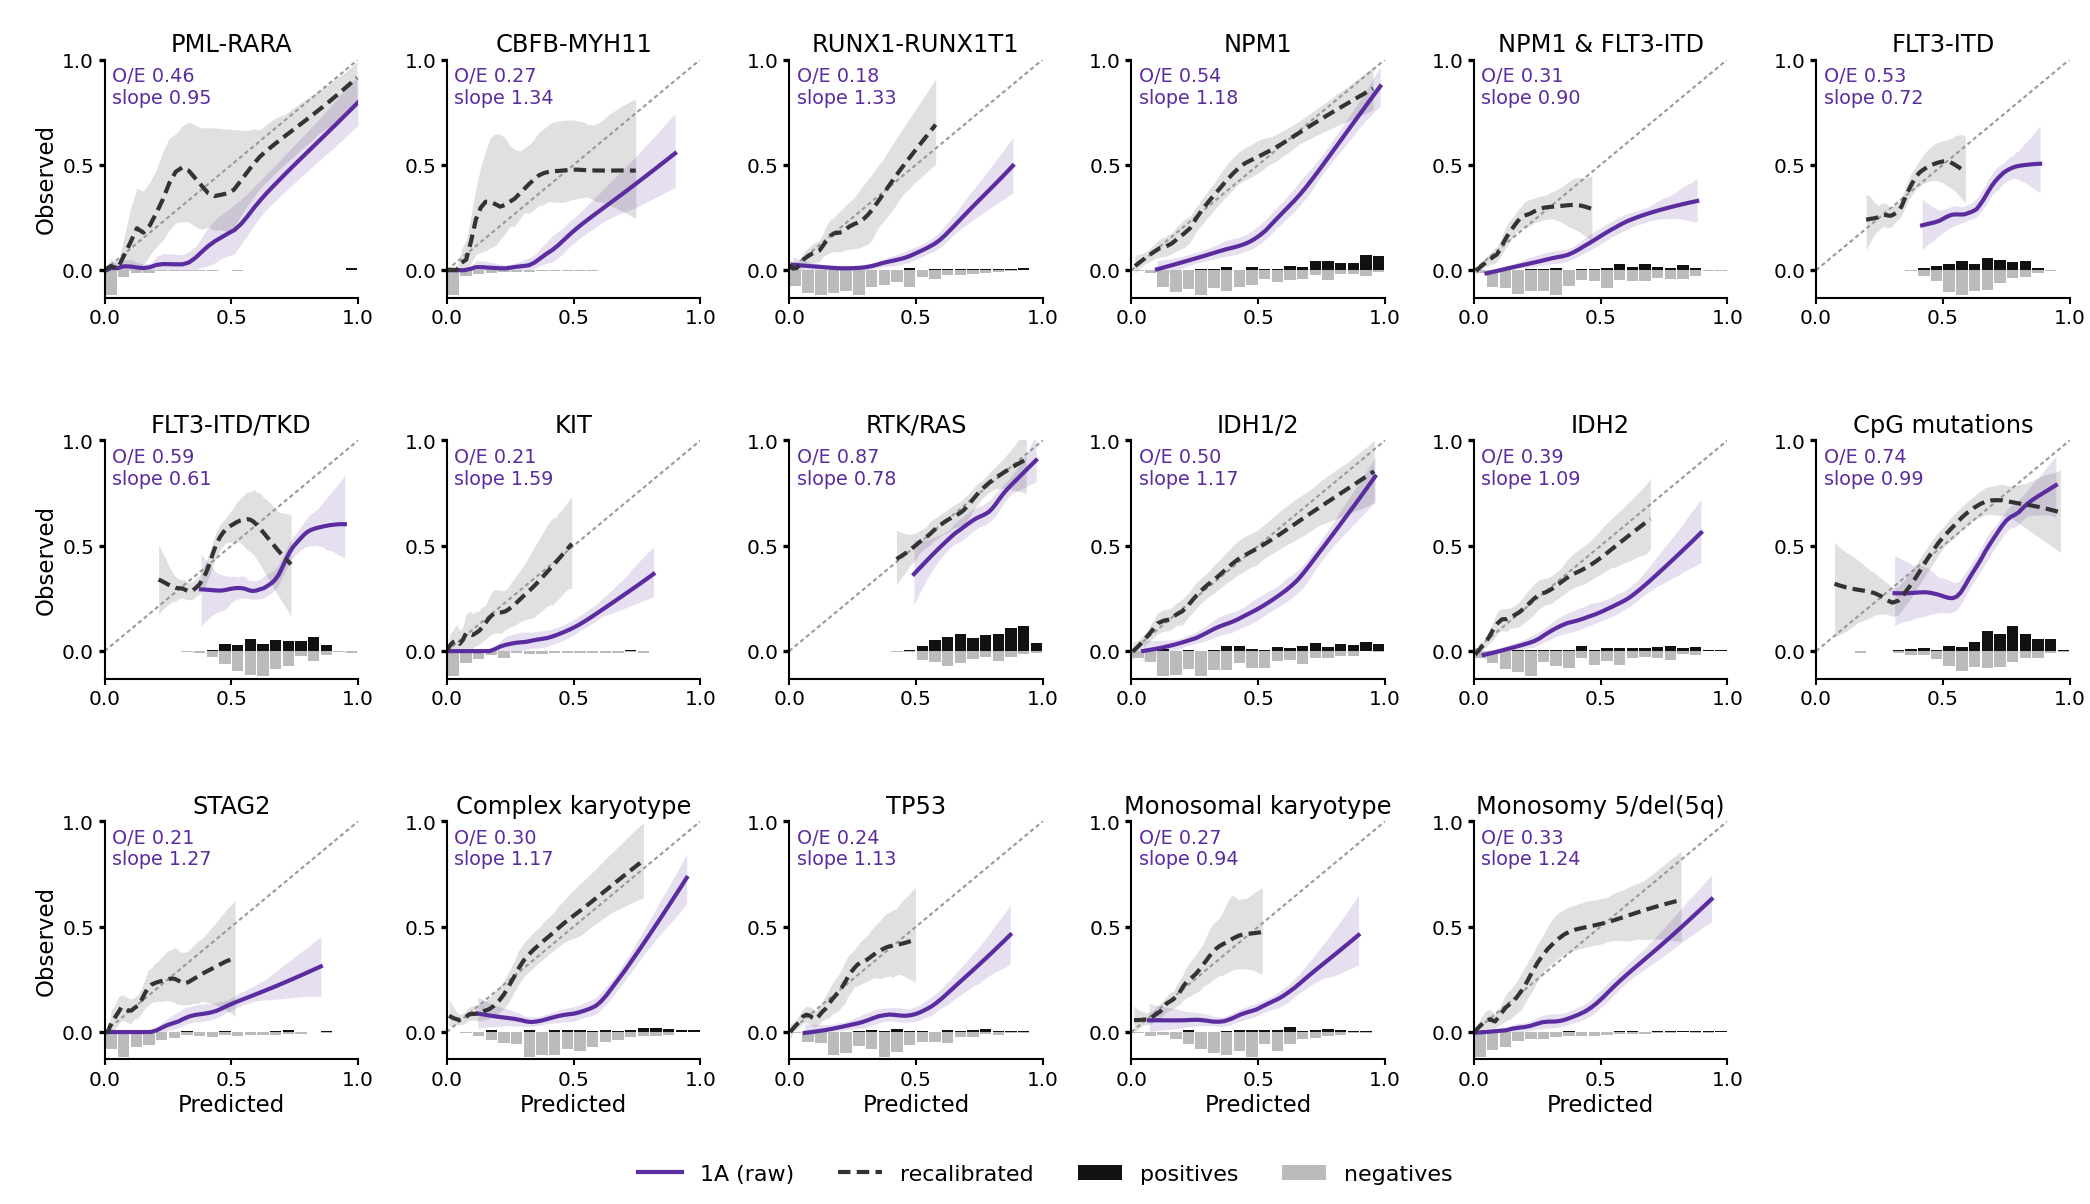

In [11]:
external(C.AML_MIL_FIGS / "supp_calibration_curves_BM", "S8_calibration_BM")

**What it shows (legend draft):** 

**Key observations:**
-

**Caveats / open questions:**
-

# Tables

## Table 1 — Cohort characteristics

*Not built yet.*

**What it shows (legend draft):** 

**Key observations:**
-

**Caveats / open questions:**
-